In [1]:
# Python tools
import dlib
from pathlib import Path
import pickle
import sys
import time

# Data and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import skfuzzy as fuzz
import cv2

# Features, models and evaluation
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    mean_squared_error,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from skimage.feature import hog
from sklearn.decomposition import PCA
from pyfume import (
    Clusterer,
    AntecedentEstimator,
    FireStrengthCalculator,
    ConsequentEstimator,
    SugenoFISBuilder,
    SugenoFISTester,
)
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from src.preprocess import preprocess_kdef_image
from sklearn.cluster import KMeans
from sklearn.base import clone
from sklearn.feature_selection import mutual_info_classif, SelectKBest, f_classif
from sklearn.pipeline import Pipeline


## Part 1
Load the data and split it in training,validation and testing sets

In [2]:
df = pd.read_csv("./data/fer2013.csv")

print( df['Usage'].value_counts() )


Training       28709
PublicTest      3589
PrivateTest     3589
Name: Usage, dtype: int64


In [3]:
# We use for training and validation the "Training" and "PublicTest"
trai_df = df[df['Usage']== 'Training'].copy()
vali_df = df[df['Usage'] == 'PublicTest'].copy()
test_df = df[df['Usage'] == 'PrivateTest'].copy() 

# Storing train and test data frames
trai_df.to_csv("./data/fer2013_train.csv", encoding='utf-8', index=False)
vali_df.to_csv("./data/fer2013_validation.csv", encoding='utf-8', index=False)
test_df.to_csv("./data/fer2013_test.csv", encoding='utf-8', index=False)


## Part 2
statistics and labelling

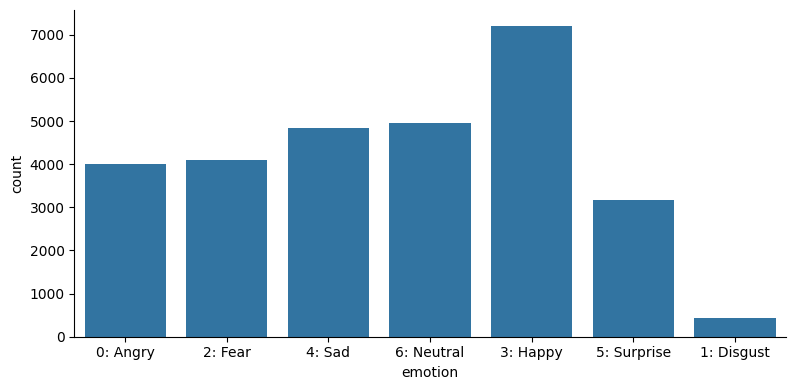

In [4]:
emotionDict = {
    0:'0: Angry',
    1:'1: Disgust',
    2:'2: Fear',
    3:'3: Happy',
    4:'4: Sad',
    5:'5: Surprise',
    6:'6: Neutral'
}


sns.catplot(data=trai_df.replace({'emotion': emotionDict}), kind='count', x='emotion', height=4, aspect=2)

plt.show()


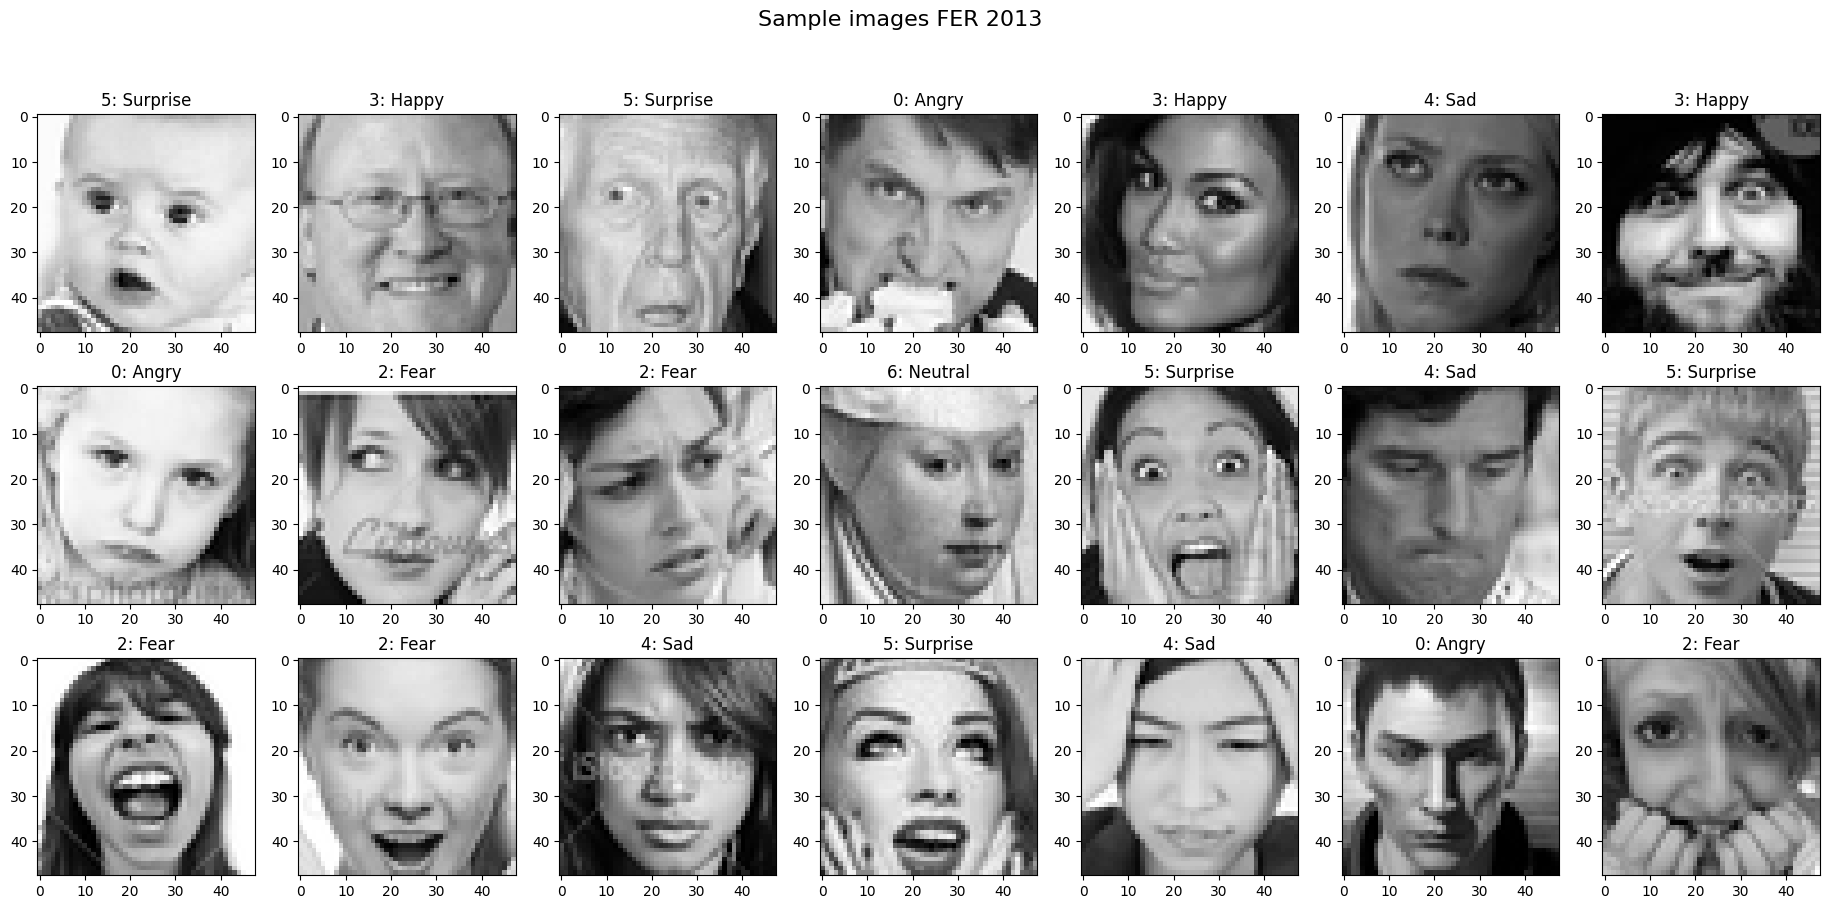

In [5]:
# Now making some plots
random_rows = df.sample(n=21, random_state=43)
imgs = [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in random_rows['pixels']]
lbl =  random_rows['emotion'].values

fig, axes = plt.subplots(nrows=3, ncols=7, figsize=(23, 10))
fig.suptitle('Sample images FER 2013', fontsize=16)

# Loop through each subplot and customize
for i in range(7):
    for j in range(3):
        ax = axes[j, i]
        ax.imshow(imgs[j*7+i], cmap="gray") 
        ax.set_title('%s'%(emotionDict[lbl[j*7+i]]))
        #ax.grid(True)
plt.show()


Compyting the class weights for the training test

In [6]:
csv_file = './data/fer2013_train.csv'
model_file = "./models/rf_fer_model_landmarks.pkl"


## Loading the Data

In [7]:
trai_df = pd.read_csv(csv_file)

# Computing class weights for unbalanced dataset
labelsTrain = trai_df['emotion'].values
cw = compute_class_weight(
    class_weight="balanced", classes=np.unique(labelsTrain), y=labelsTrain)
#class_weights = {0:cw[0],1:cw[1],2:cw[2], 3:cw[3], 4:cw[4], 5:cw[5], 6:cw[6]}


## Feature extraction pipeline

In [8]:
# Importing dlib's landmark detector
# Dlib landmarks from: 
#   https://github.com/davisking/dlib-models/blob/master/shape_predictor_68_face_landmarks.dat.bz2
landmDet = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat")


def extractLandmarksFER(images):
    face_rects = dlib.rectangle(left=1, top=1, right=47, bottom=47)
    x1 = face_rects.left() 
    y1 = face_rects.top() 
    x2 = face_rects.right() 
    y2 = face_rects.bottom()

    landm = []
    for img in images:
        la = landmDet(img.astype(np.uint8), face_rects)

        # This works better if the standard scaler is not usec
        la2 = np.asarray( np.matrix([
            [
                (p.x-0.5*(x2-x1))/(x2-x1), (p.y-0.5*(y2-y1))/(y2-y1)
            ] for p in la.parts()])).astype(np.float32)
        la2 -= np.mean(la2, axis=0, keepdims=True)
        la2 /= np.max(np.abs(la2), axis=0, keepdims=True)

        landm.append(la2.flatten())
    feats = np.stack(landm)
    return(feats)

# Loading the images
images = np.array(
        [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in trai_df['pixels']])
feats = extractLandmarksFER(images)

images = None


## Evaluating the results

Random Forest + Landmarks

In [9]:
rf = RandomForestClassifier(
    n_estimators=300,       # Number of trees
    max_depth=11,           # Allow trees to grow fully
    max_features='sqrt',   # Use sqrt(features) for splitting
    random_state=42,
    n_jobs=-1,             # Use all available CPU cores 
    #class_weight= "balanced", #class_weights,
    criterion="entropy",
)


rf.fit(feats, trai_df['emotion'].values)

joblib.dump(rf, model_file)
print(f"Model saved to {model_file}")


Model saved to ./models/rf_fer_model_landmarks.pkl


Perform to validation test and Confusion Matrix Random Forest + Landmarks

Accuracy: 0.48
Balanced accuracy: 0.41
Macro F1: 0.41


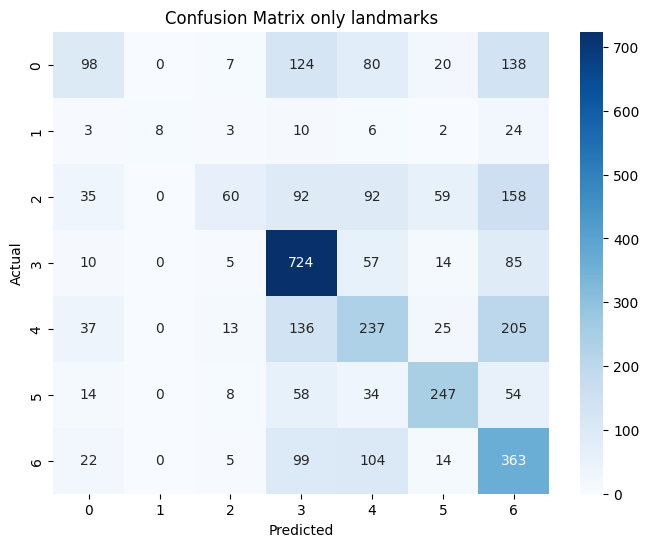

In [10]:
def preprocessingFer(dataFrame):
    # Convert pixel strings to 48x48 images
    images = np.array(
        [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in dataFrame['pixels']])
    X =  extractLandmarksFER(images)
    y = dataFrame['emotion'].values
    return([X,y])


# Predict and evaluate
valid = pd.read_csv('./data/fer2013_validation.csv')
X_valid, y_valid = preprocessingFer(valid)

y_pred = rf.predict(X_valid)
accuracy = accuracy_score(y_valid, y_pred)
conf_matrix = confusion_matrix(y_valid, y_pred)

baccuracy = balanced_accuracy_score(y_valid, y_pred)
macro_f1 = f1_score(y_valid, y_pred, average='macro')


# Print results
print(f"Accuracy: {accuracy:.2f}")
print(f"Balanced accuracy: {baccuracy:.2f}")
print(f"Macro F1: {macro_f1:.2f}")


plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix only landmarks")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Logistic Regression + Landmarks

In [11]:
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(feats, labelsTrain)

print("Logistic Regression trained successfully")


Logistic Regression trained successfully


Evaluate Logistic Regression + Landmarks on the Validation Set

In [12]:
y_pred_lr = lr.predict(X_valid)

accuracy_lr = accuracy_score(y_valid, y_pred_lr)
baccuracy_lr = balanced_accuracy_score(y_valid, y_pred_lr)
macro_f1_lr = f1_score(y_valid, y_pred_lr, average='macro')

conf_matrix_lr = confusion_matrix(y_valid, y_pred_lr)

print(f"Accuracy: {accuracy_lr:.2f}")
print(f"Balanced accuracy: {baccuracy_lr:.2f}")
print(f"Macro F1: {macro_f1_lr:.2f}")


Accuracy: 0.48
Balanced accuracy: 0.39
Macro F1: 0.38


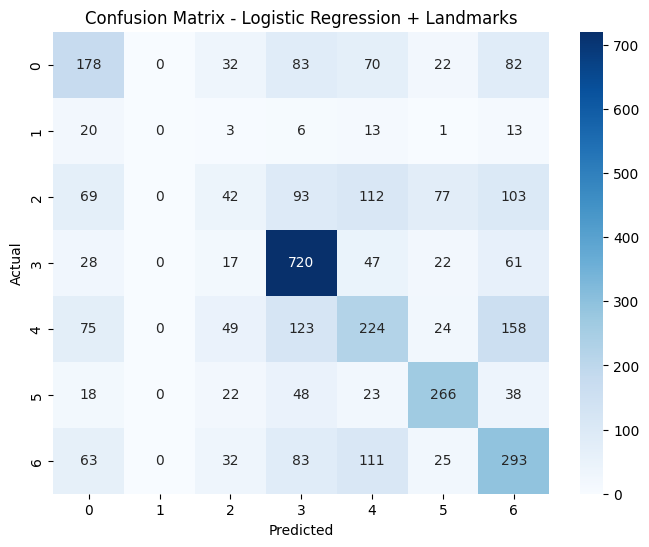

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_lr, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression + Landmarks")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


SVM + Landmarks

In [14]:
svm = SVC(
    kernel='rbf',
    random_state=42
)

svm.fit(feats, labelsTrain)

print("SVM trained successfully")


SVM trained successfully


Validation

In [15]:
# Evaluate SVM on the Validation Set

y_pred_svm = svm.predict(X_valid)

accuracy_svm = accuracy_score(y_valid, y_pred_svm)
baccuracy_svm = balanced_accuracy_score(y_valid, y_pred_svm)
macro_f1_svm = f1_score(y_valid, y_pred_svm, average='macro')

conf_matrix_svm = confusion_matrix(y_valid, y_pred_svm)

print(f"Accuracy: {accuracy_svm:.2f}")
print(f"Balanced accuracy: {baccuracy_svm:.2f}")
print(f"Macro F1: {macro_f1_svm:.2f}")


Accuracy: 0.46
Balanced accuracy: 0.37
Macro F1: 0.35


Confusion Matrix

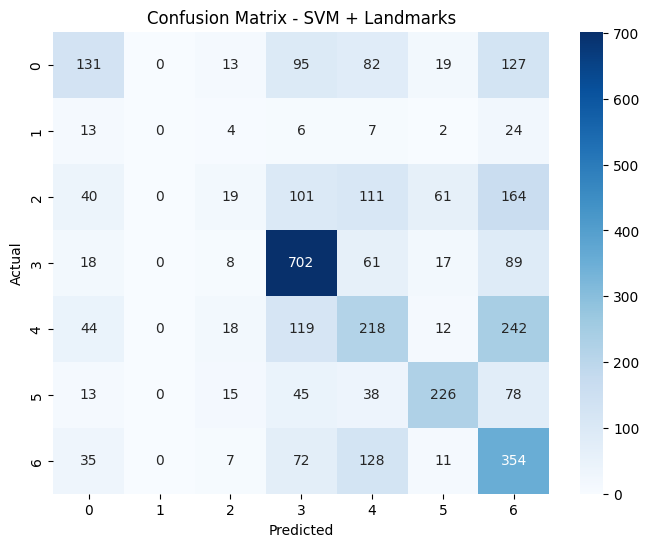

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - SVM + Landmarks")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## HOG Feature extraction

In [17]:
def extractHOG(images):
    hog_features = []

    for img in images:
        features = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys'
        )
        hog_features.append(features)

    return np.array(hog_features)


Extract training features

In [18]:
##Extract HOG features from the training images

images_train = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in trai_df['pixels']]
)

hog_feats = extractHOG(images_train)

images_train = None

print("HOG feature shape:", hog_feats.shape)


HOG feature shape: (28709, 900)


Random Forest + HOG

In [ ]:
# Random Forest + HOG

rf_hog = RandomForestClassifier(
    n_estimators=300,
    max_depth=11,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1,
    criterion="entropy"
)

rf_hog.fit(hog_feats, labelsTrain)

print("Random Forest + HOG trained successfully")


Validation Random Forest + HOG

In [ ]:
images_valid = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in valid['pixels']]
)

hog_valid = extractHOG(images_valid)

images_valid = None

y_pred_rf_hog = rf_hog.predict(hog_valid)

accuracy_rf_hog = accuracy_score(y_valid, y_pred_rf_hog)
baccuracy_rf_hog = balanced_accuracy_score(y_valid, y_pred_rf_hog)
macro_f1_rf_hog = f1_score(y_valid, y_pred_rf_hog, average='macro')

conf_matrix_rf_hog = confusion_matrix(y_valid, y_pred_rf_hog)

print(f"Accuracy: {accuracy_rf_hog:.2f}")
print(f"Balanced accuracy: {baccuracy_rf_hog:.2f}")
print(f"Macro F1: {macro_f1_rf_hog:.2f}")


Accuracy: 0.45
Balanced accuracy: 0.38
Macro F1: 0.39


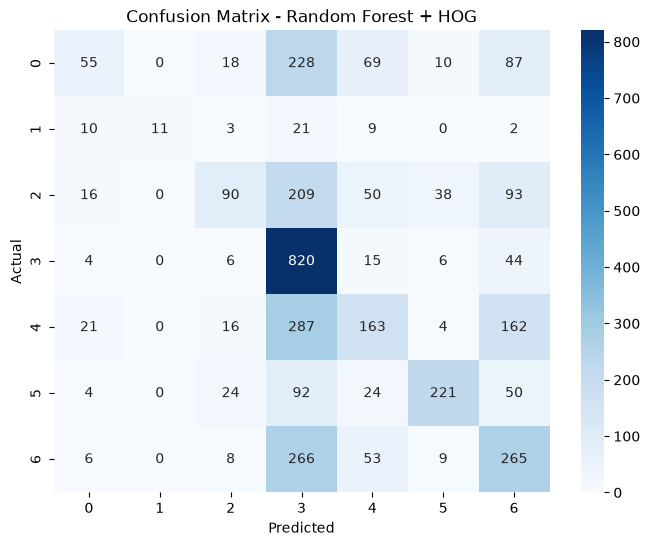

In [ ]:
## Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_rf_hog, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Random Forest + HOG")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Logistic Regression + HOG

Scaling

In [ ]:
scaler_hog = StandardScaler()

hog_feats_scaled = scaler_hog.fit_transform(hog_feats)

print("Scaled HOG shape:", hog_feats_scaled.shape)


Scaled HOG shape: (28709, 900)


In [ ]:
lr_hog = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_hog.fit(hog_feats_scaled, labelsTrain)

print("Logistic Regression + HOG trained successfully")


Logistic Regression + HOG trained successfully


Validation Test Logistic Regression + HOG

In [ ]:
hog_valid_scaled = scaler_hog.transform(hog_valid)

y_pred_lr_hog = lr_hog.predict(hog_valid_scaled)

accuracy_lr_hog = accuracy_score(y_valid, y_pred_lr_hog)
baccuracy_lr_hog = balanced_accuracy_score(y_valid, y_pred_lr_hog)
macro_f1_lr_hog = f1_score(y_valid, y_pred_lr_hog, average='macro')

conf_matrix_lr_hog = confusion_matrix(y_valid, y_pred_lr_hog)

print(f"Accuracy: {accuracy_lr_hog:.2f}")
print(f"Balanced accuracy: {baccuracy_lr_hog:.2f}")
print(f"Macro F1: {macro_f1_lr_hog:.2f}")


Accuracy: 0.43
Balanced accuracy: 0.40
Macro F1: 0.39


Confusion Matrix Logistic Regression + HOG

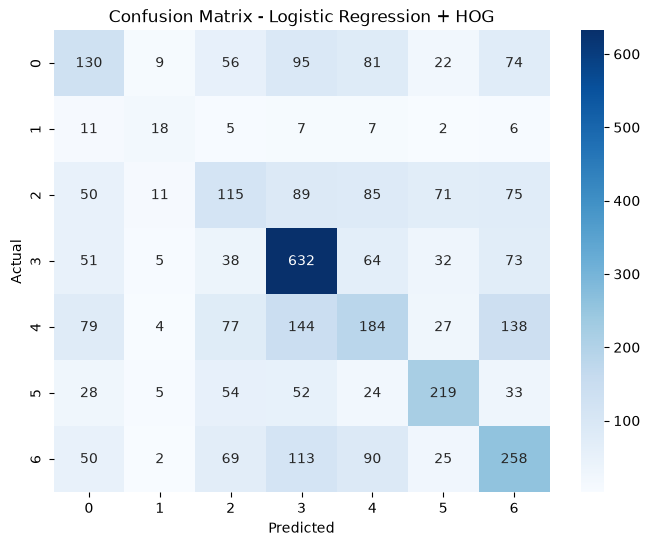

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_lr_hog, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression + HOG")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


SVM + HOG

In [ ]:
svm_hog = SVC(
    kernel='rbf',
    random_state=42
)

svm_hog.fit(hog_feats, labelsTrain)

print("SVM + HOG trained successfully")


SVM + HOG trained successfully


Validation Test SVM + HOG

In [ ]:
y_pred_svm_hog = svm_hog.predict(hog_valid)

accuracy_svm_hog = accuracy_score(y_valid, y_pred_svm_hog)
baccuracy_svm_hog = balanced_accuracy_score(y_valid, y_pred_svm_hog)
macro_f1_svm_hog = f1_score(y_valid, y_pred_svm_hog, average='macro')

conf_matrix_svm_hog = confusion_matrix(y_valid, y_pred_svm_hog)

print(f"Accuracy: {accuracy_svm_hog:.2f}")
print(f"Balanced accuracy: {baccuracy_svm_hog:.2f}")
print(f"Macro F1: {macro_f1_svm_hog:.2f}")


Accuracy: 0.54
Balanced accuracy: 0.47
Macro F1: 0.50


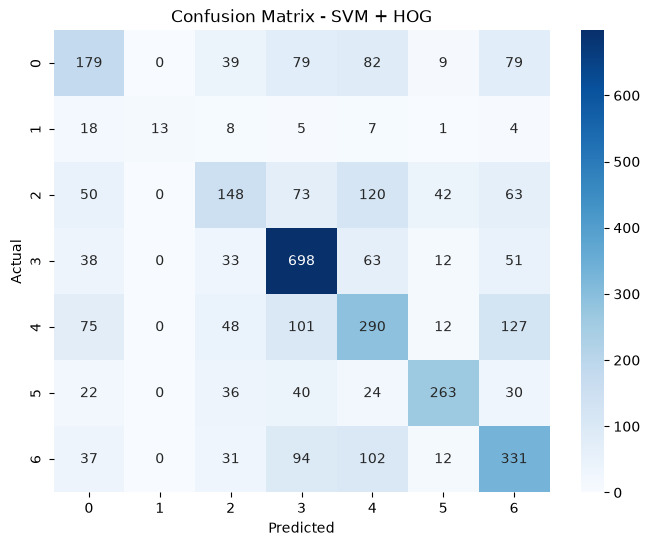

In [ ]:
##Confusion Matrix

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svm_hog, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - SVM + HOG")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## PCA

In [ ]:
# Prepare training images as flattened pixel vectors

images_train = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in trai_df['pixels']]
)

X_pixels_train = images_train.reshape(len(images_train), -1)

images_train = None

print("Original feature shape:", X_pixels_train.shape)


Original feature shape: (28709, 2304)


In [ ]:
pca = PCA(
    n_components=0.95,
    random_state=42
)

X_pca_train = pca.fit_transform(X_pixels_train)

print("PCA feature shape:", X_pca_train.shape)
print(f"Explained variance: {pca.explained_variance_ratio_.sum():.2f}")


PCA feature shape: (28709, 253)
Explained variance: 0.95


Scaling

In [ ]:
scaler_pca = StandardScaler()

X_pca_train_scaled = scaler_pca.fit_transform(X_pca_train)


Logistic Regression + PCA

In [ ]:
lr_pca = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_pca.fit(X_pca_train_scaled, labelsTrain)

print("Logistic Regression + PCA trained successfully")


Logistic Regression + PCA trained successfully


Evaluate Logistic Regression + PCA on the Validation Set

In [ ]:
images_valid = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in valid['pixels']]
)

X_pixels_valid = images_valid.reshape(len(images_valid), -1)

images_valid = None

# Apply the already-fitted PCA
X_pca_valid = pca.transform(X_pixels_valid)

# Apply the already-fitted scaler
X_pca_valid_scaled = scaler_pca.transform(X_pca_valid)

y_pred_lr_pca = lr_pca.predict(X_pca_valid_scaled)

accuracy_lr_pca = accuracy_score(y_valid, y_pred_lr_pca)
baccuracy_lr_pca = balanced_accuracy_score(y_valid, y_pred_lr_pca)
macro_f1_lr_pca = f1_score(y_valid, y_pred_lr_pca, average='macro')

conf_matrix_lr_pca = confusion_matrix(y_valid, y_pred_lr_pca)

print(f"Accuracy: {accuracy_lr_pca:.2f}")
print(f"Balanced accuracy: {baccuracy_lr_pca:.2f}")
print(f"Macro F1: {macro_f1_lr_pca:.2f}")


Accuracy: 0.38
Balanced accuracy: 0.30
Macro F1: 0.29


Confusion Matrix - Logistic Regression + PCA

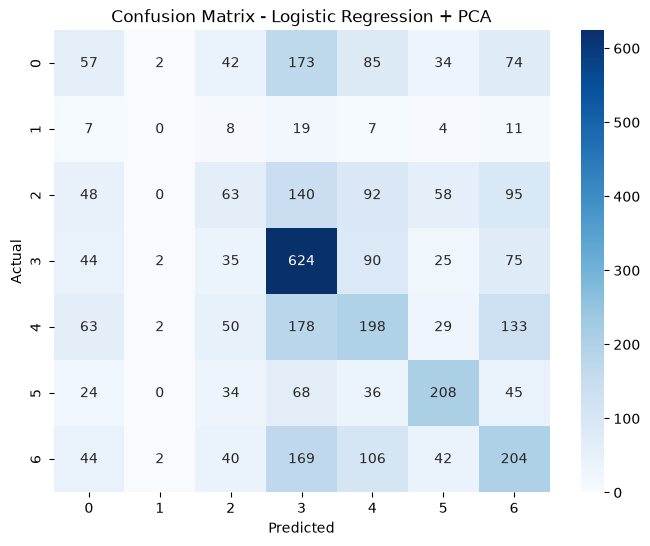

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_lr_pca, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression + PCA")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Random Forest + PCA

In [ ]:
rf_pca = RandomForestClassifier(
    n_estimators=300,
    max_depth=11,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1,
    criterion="entropy"
)

rf_pca.fit(X_pca_train, labelsTrain)

print("Random Forest + PCA trained successfully")


Random Forest + PCA trained successfully


Evaluate Random Forest + PCA in the validation test

In [ ]:
y_pred_rf_pca = rf_pca.predict(X_pca_valid)

accuracy_rf_pca = accuracy_score(y_valid, y_pred_rf_pca)
baccuracy_rf_pca = balanced_accuracy_score(y_valid, y_pred_rf_pca)
macro_f1_rf_pca = f1_score(y_valid, y_pred_rf_pca, average='macro')

conf_matrix_rf_pca = confusion_matrix(y_valid, y_pred_rf_pca)

print(f"Accuracy: {accuracy_rf_pca:.2f}")
print(f"Balanced accuracy: {baccuracy_rf_pca:.2f}")
print(f"Macro F1: {macro_f1_rf_pca:.2f}")


Accuracy: 0.35
Balanced accuracy: 0.27
Macro F1: 0.26


Confusion Matrix - Random Forest + PCA

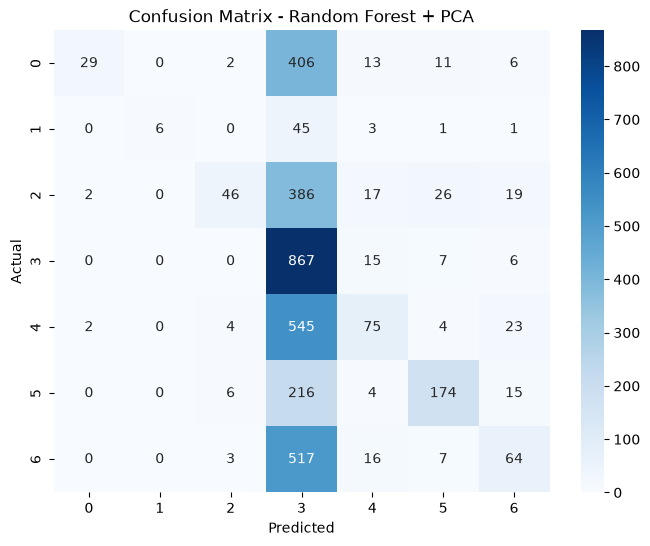

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_rf_pca, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Random Forest + PCA")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


SVM + PCA

In [ ]:
svm_pca = SVC(
    kernel='rbf',
    random_state=42
)

svm_pca.fit(X_pca_train_scaled, labelsTrain)

print("SVM + PCA trained successfully")


SVM + PCA trained successfully


Evaluate SVM + PCA in the validation test

In [ ]:
y_pred_svm_pca = svm_pca.predict(X_pca_valid_scaled)

accuracy_svm_pca = accuracy_score(y_valid, y_pred_svm_pca)
baccuracy_svm_pca = balanced_accuracy_score(y_valid, y_pred_svm_pca)
macro_f1_svm_pca = f1_score(y_valid, y_pred_svm_pca, average='macro')

conf_matrix_svm_pca = confusion_matrix(y_valid, y_pred_svm_pca)

print(f"Accuracy: {accuracy_svm_pca:.2f}")
print(f"Balanced accuracy: {baccuracy_svm_pca:.2f}")
print(f"Macro F1: {macro_f1_svm_pca:.2f}")


Accuracy: 0.45
Balanced accuracy: 0.38
Macro F1: 0.40


Confusion Matrix - SVM + PCA

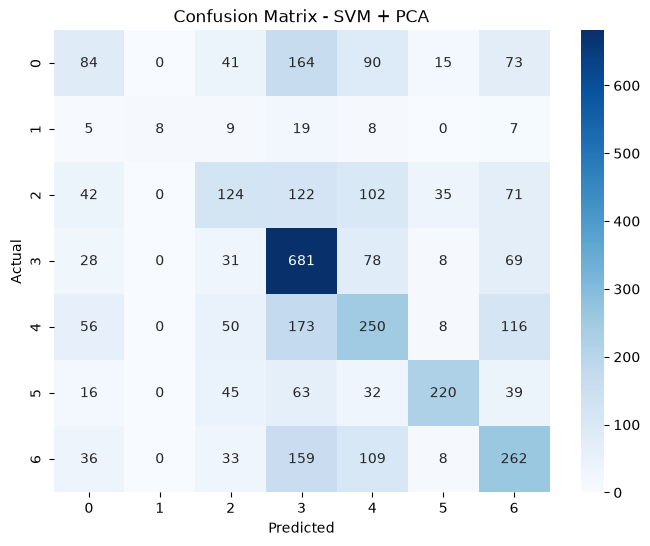

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svm_pca, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - SVM + PCA")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
BASE = Path(".")

with (BASE / "data/kdef_preprocessed.pkl").open("rb") as f:
    data = pickle.load(f)

np.savez_compressed(
    BASE / "data/kdef_preprocessed.npz",
    X_train=data["X_train"],
    y_train=data["y_train"],
    X_test=data["X_test"],
    y_test=data["y_test"]
)


In [ ]:
BASE = Path(".")

with np.load(
    BASE / "data/kdef_preprocessed.npz",
    allow_pickle=False
) as data:
    X_train = data["X_train"].astype(np.float32)
    y_train = data["y_train"]
    X_test = data["X_test"].astype(np.float32)
    y_test = data["y_test"]

print("Training:", X_train.shape)
print("Test:", X_test.shape)


Training: (784, 48, 48)
Test: (196, 48, 48)


In [ ]:
def normalize_images(images):
    images = np.asarray(images, dtype=np.float32)

    if not np.isfinite(images).all():
        raise ValueError("Images contain NaN or infinite values.")

    minimum = images.min()
    maximum = images.max()

    if minimum < 0 or maximum > 255:
        raise ValueError(f"Unexpected pixel range: {minimum} to {maximum}")

    if maximum > 1:
        images = images / 255.0

    return images


X_train = normalize_images(X_train)
X_test = normalize_images(X_test)

print("Training:", X_train.shape, X_train.min(), X_train.max())
print("Test:", X_test.shape, X_test.min(), X_test.max())


Training: (784, 48, 48) 0.015686275 0.98039216
Test: (196, 48, 48) 0.015686275 0.9529412


In [ ]:
predictor_path = (
    BASE / "faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat"
)

landmark_predictor = dlib.shape_predictor(str(predictor_path))


def extract_landmarks(img):
    img_uint8 = np.ascontiguousarray(
        np.round(img * 255).astype(np.uint8)
    )

    height, width = img_uint8.shape

    # The saved image is already a cropped face
    face_rect = dlib.rectangle(0, 0, width - 1, height - 1)

    shape = landmark_predictor(img_uint8, face_rect)

    return np.array(
        [(point.x, point.y) for point in shape.parts()],
        dtype=np.float32
    )


landmarks_train = np.stack([
    extract_landmarks(img) for img in X_train
])

landmarks_test = np.stack([
    extract_landmarks(img) for img in X_test
])

print("Training landmarks:", landmarks_train.shape)
print("Test landmarks:", landmarks_test.shape)


Training landmarks: (784, 68, 2)
Test landmarks: (196, 68, 2)


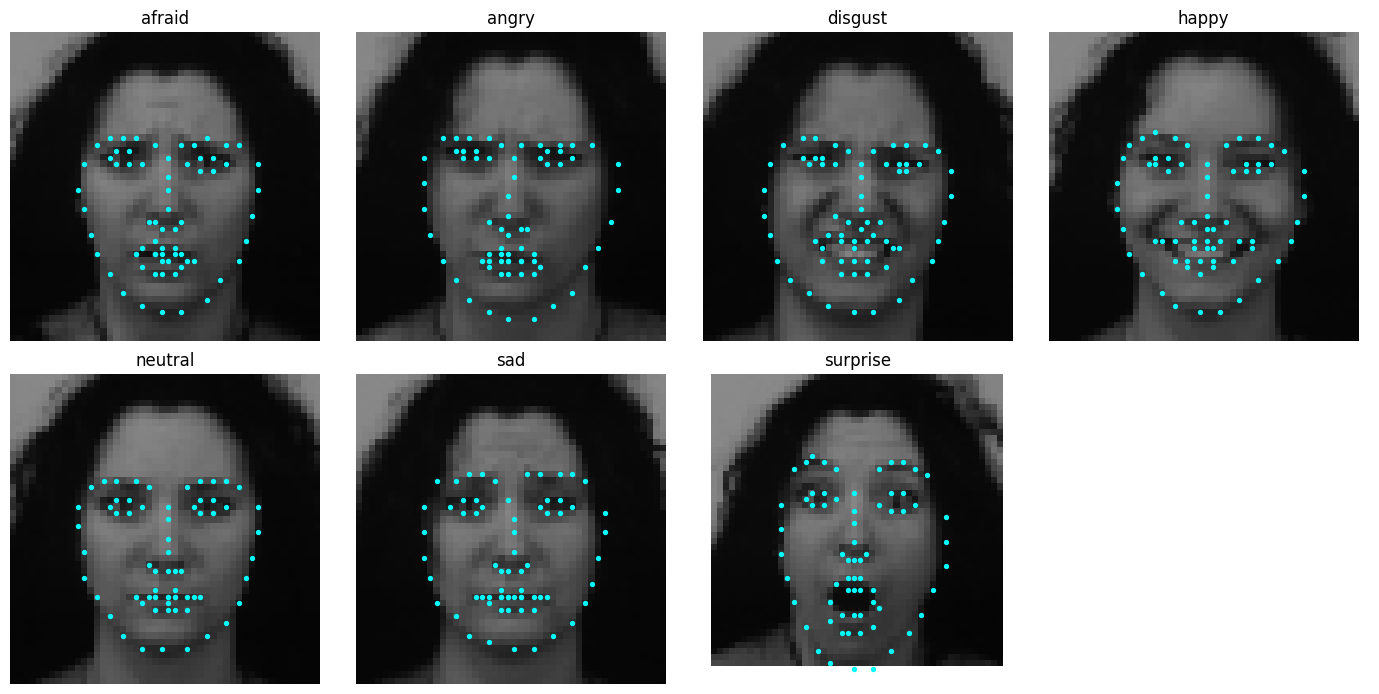

In [ ]:
emotions = np.unique(y_train)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, emotion in zip(axes.ravel(), emotions):
    idx = np.flatnonzero(y_train == emotion)[0]
    points = landmarks_train[idx]

    ax.imshow(X_train[idx], cmap="gray", vmin=0, vmax=1)
    ax.scatter(points[:, 0], points[:, 1], s=8, color="cyan")
    ax.set_title(emotion)
    ax.axis("off")

for ax in axes.ravel()[len(emotions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
FEATURE_NAMES = [
    "mouth_opening",
    "mouth_width",
    "eye_opening",
    "eyebrow_height",
    "brow_separation",
    "smile_curvature",
    "mouth_aspect_ratio",
    "inner_brow_elevation"
]


def geometric_features(points):
    def distance(a, b):
        return np.linalg.norm(a - b)

    # Eye centres
    eye_left = points[36:42].mean(axis=0)
    eye_right = points[42:48].mean(axis=0)

    # Rotate coordinates so the eye centres lie horizontally.
    # This reduces the effect of head tilt.
    eye_vector = eye_right - eye_left
    scale = np.linalg.norm(eye_vector)

    if scale < 1e-6:
        raise ValueError("Eye centres are too close: inspect the landmarks.")

    horizontal = eye_vector / scale
    vertical = np.array([-horizontal[1], horizontal[0]])

    centred = points - (eye_left + eye_right) / 2
    p = np.column_stack([
        centred @ horizontal,
        centred @ vertical
    ])

    # Average of three inner-lip distances
    mouth_opening = np.mean([
        distance(p[61], p[67]),
        distance(p[62], p[66]),
        distance(p[63], p[65]),
    ]) / scale

    mouth_width = distance(p[48], p[54]) / scale

    if mouth_width < 1e-6:
        raise ValueError("Invalid mouth width: inspect the landmarks.")

    mouth_aspect_ratio = mouth_opening / mouth_width

    # Average of two opening measurements per eye
    eye_opening = np.mean([
        distance(p[37], p[41]),
        distance(p[38], p[40]),
        distance(p[43], p[47]),
        distance(p[44], p[46]),
    ]) / scale

    # Image y coordinates increase downwards:
    # eye height minus eyebrow height is normally positive.
    eyebrow_height = np.mean([
        p[36:42, 1].mean() - p[17:22, 1].mean(),
        p[42:48, 1].mean() - p[22:27, 1].mean(),
    ]) / scale

    brow_separation = distance(p[21], p[22]) / scale

    # Positive when mouth corners sit above the lip centre
    lip_centre_y = (p[51, 1] + p[57, 1]) / 2
    corners_y = (p[48, 1] + p[54, 1]) / 2
    smile_curvature = (lip_centre_y - corners_y) / scale

    # 17 and 26: outer eyebrow ends
    # 21 and 22: inner eyebrow ends

    inner_brow_elevation = np.mean([
        p[17, 1] - p[21, 1],
        p[26, 1] - p[22, 1],
    ]) / scale

    return np.array([
        mouth_opening,
        mouth_width,
        eye_opening,
        eyebrow_height,
        brow_separation,
        smile_curvature,
        mouth_aspect_ratio,
        inner_brow_elevation
    ])


In [ ]:
geometry_train = np.stack([
    geometric_features(points)
    for points in landmarks_train
])

features_train_df = pd.DataFrame(
    geometry_train,
    columns=FEATURE_NAMES
)

features_train_df["emotion"] = y_train

assert np.isfinite(geometry_train).all()

print("Training feature shape:", geometry_train.shape)
features_train_df.head(10)


Training feature shape: (784, 8)


,mouth_opening,mouth_width,eye_opening,eyebrow_height,brow_separation,smile_curvature,mouth_aspect_ratio,inner_brow_elevation,emotion
0,0.062575,0.704131,0.155517,0.232583,0.311033,0.041317,0.088868,9.269513e-09,afraid
1,0.025622,0.696053,0.115299,0.166125,0.230599,0.001477,0.036810,-4.135894e-02,angry
2,0.202127,0.988281,0.083647,0.214427,0.303191,0.153687,0.204524,-3.782317e-02,disgust
3,0.155774,1.083080,0.090257,0.264156,0.433232,0.180304,0.143825,3.606082e-02,happy
4,0.025641,0.769231,0.153846,0.276923,0.461538,0.076923,0.033333,0.000000e+00,neutral
5,0.025000,0.825000,0.150000,0.345000,0.382427,0.075000,0.030303,3.750001e-02,sad
6,0.314462,0.627382,0.194543,0.453793,0.544720,0.002019,0.501229,3.683768e-02,surprise
7,0.196991,0.886460,0.073872,0.289222,0.369358,0.110505,0.222222,1.132333e-01,afraid
8,0.000000,0.768978,0.115347,0.287385,0.317058,0.036465,0.000000,3.942182e-02,angry
9,0.000000,0.661802,0.091355,0.273353,0.438503,0.074777,0.000000,-3.649850e-02,disgust


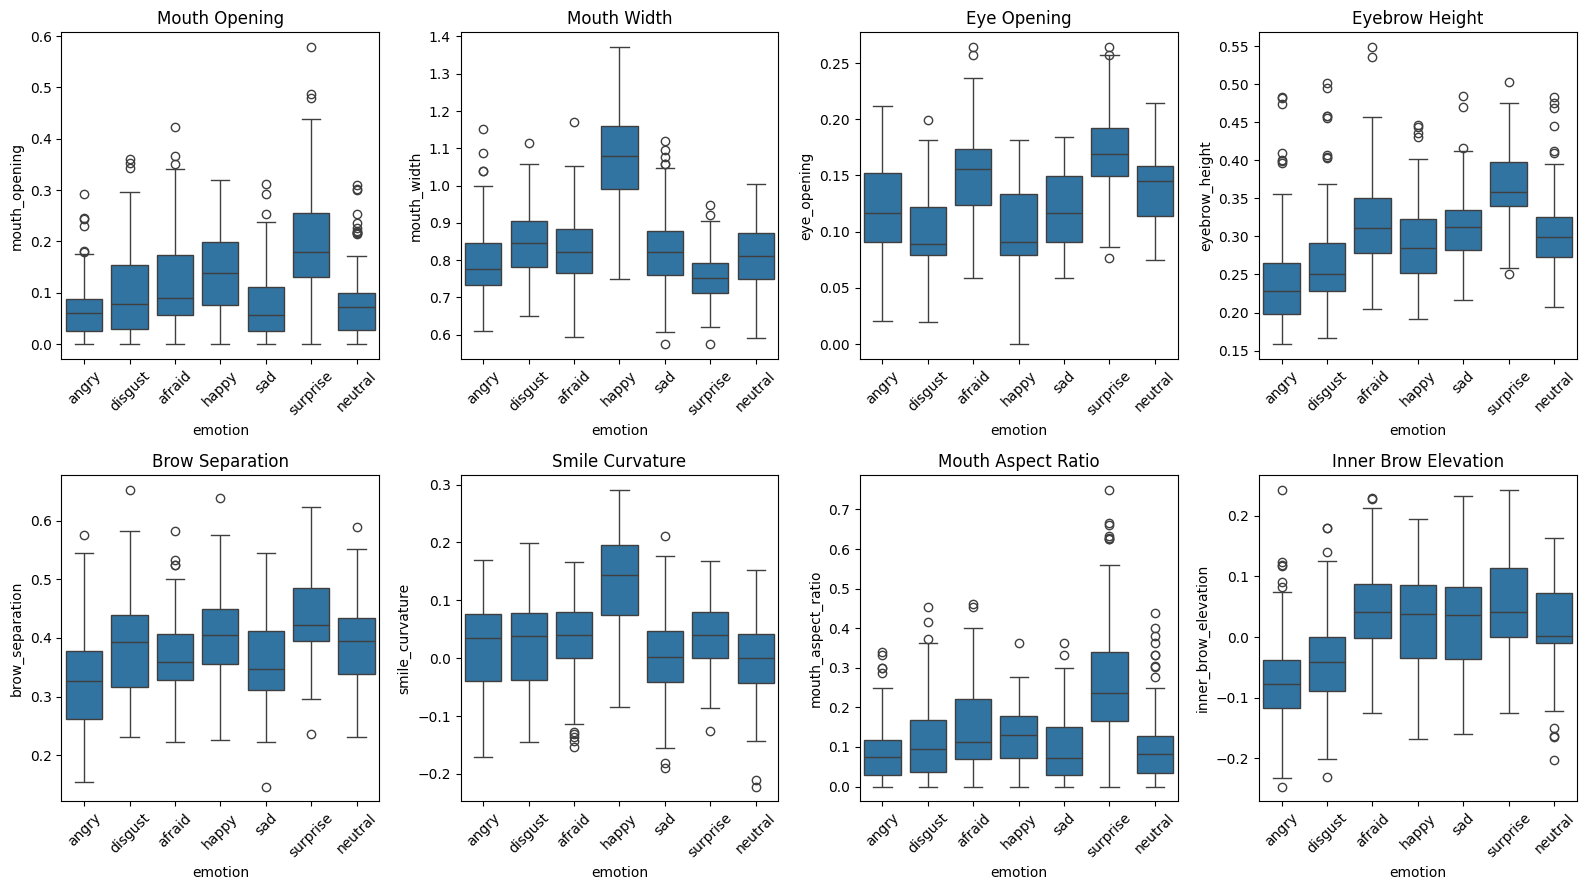

In [ ]:
emotion_order = [
    "angry", "disgust", "afraid",
    "happy", "sad", "surprise", "neutral"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for ax, feature in zip(axes.ravel(), FEATURE_NAMES):
    sns.boxplot(
        data=features_train_df,
        x="emotion",
        y=feature,
        order=emotion_order,
        ax=ax
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
# Membership definitions:
# Compare this version using training/validation subjects.
fuzzy_sets = {}

for feature in FEATURE_NAMES:
    values = features_train_df[feature].to_numpy()

    minimum = values.min()
    low, middle, high = np.percentile(values, [10, 50, 90])
    maximum = values.max()

    if not low < middle < high:
        raise ValueError(
            f"{feature}: inspect the distribution "
            "and choose thresholds manually."
        )

    universe = np.unique(np.concatenate([
        np.linspace(minimum, maximum, 301),
        [low, middle, high]
    ]))

    fuzzy_sets[feature] = {
        "range": universe,

        "low": fuzz.trapmf(
            universe,
            [minimum, minimum, low, middle]
        ),

        "medium": fuzz.trimf(
            universe,
            [low, middle, high]
        ),

        "high": fuzz.trapmf(
            universe,
            [middle, high, maximum, maximum]
        ),
    }


In [ ]:
EMOTIONS = [
    "angry", "disgust", "afraid", "happy",
    "sad", "surprise", "neutral"
]

x_support = np.linspace(0, 1, 201)

#Triangular-function approach 
y_support_low = fuzz.trimf(x_support, [0, 0, 0.5])
y_support_high = fuzz.trimf(x_support, [0.5, 1, 1])


In [ ]:
RULES = {
    "happy": [
        [
            ("smile_curvature", "high"),
            ("mouth_width", "high"),
        ],
        [
            ("smile_curvature", "high"),
            ("eye_opening", "low"),
        ],
    ],

    "surprise": [
        [
            ("mouth_opening", "high"),
            ("eye_opening", "high"),
            ("eyebrow_height", "high"),
        ],
    ],

    "afraid": [
        [
            ("eye_opening", "high"),
            ("eyebrow_height", "medium"),
            ("mouth_opening", "medium"),
        ],
    ],

    "angry": [
        [
            ("eyebrow_height", "low"),
            ("brow_separation", "low"),
            ("smile_curvature", "low"),
        ],
        [
            ("eyebrow_height", "low"),
            ("eye_opening", "low"),
            ("mouth_opening", "low"),
        ],
    ],

    "disgust": [
        [
            ("eye_opening", "low"),
            ("mouth_opening", "medium"),
            ("smile_curvature", "medium"),
        ],
    ],

    "sad": [
        [
            ("inner_brow_elevation", "high"),
            ("mouth_opening", "low"),
            ("smile_curvature", "low"),
        ],
    ],

    "neutral": [
        [
            ("smile_curvature", "medium"),
            ("eye_opening", "medium"),
            ("eyebrow_height", "medium"),
            ("mouth_aspect_ratio", "medium")
        ],
    ],
}

for emotion, rules in RULES.items():
    for number, conditions in enumerate(rules, start=1):
        text = " AND ".join(
            f"{feature} is {term}"
            for feature, term in conditions
        )
        print(f"{emotion}, rule {number}: IF {text} THEN support is high")


happy, rule 1: IF smile_curvature is high AND mouth_width is high THEN support is high
happy, rule 2: IF smile_curvature is high AND eye_opening is low THEN support is high
surprise, rule 1: IF mouth_opening is high AND eye_opening is high AND eyebrow_height is high THEN support is high
afraid, rule 1: IF eye_opening is high AND eyebrow_height is medium AND mouth_opening is medium THEN support is high
angry, rule 1: IF eyebrow_height is low AND brow_separation is low AND smile_curvature is low THEN support is high
angry, rule 2: IF eyebrow_height is low AND eye_opening is low AND mouth_opening is low THEN support is high
disgust, rule 1: IF eye_opening is low AND mouth_opening is medium AND smile_curvature is medium THEN support is high
sad, rule 1: IF inner_brow_elevation is high AND mouth_opening is low AND smile_curvature is low THEN support is high
neutral, rule 1: IF smile_curvature is medium AND eye_opening is medium AND eyebrow_height is medium AND mouth_aspect_ratio is medium T

In [ ]:
def fuzzify_features(feature_values):
    feature_values = np.asarray(feature_values, dtype=float)

    if feature_values.shape != (len(FEATURE_NAMES),):
        raise ValueError("Expected one vector containing six features.")

    if not np.isfinite(feature_values).all():
        raise ValueError("Feature values must be finite.")

    memberships = {}

    for feature, value in zip(FEATURE_NAMES, feature_values):
        sets = fuzzy_sets[feature]
        universe = sets["range"]

        # Test measurements can exceed the training range.
        # Clip to the nearest boundary instead of giving all terms zero.
        value = np.clip(value, universe[0], universe[-1])

        memberships[feature] = {
            term: float(fuzz.interp_membership(
                universe,
                sets[term],
                value
            ))
            for term in ["low", "medium", "high"]
        }

    return memberships


In [ ]:
print(FEATURE_NAMES)


['mouth_opening', 'mouth_width', 'eye_opening', 'eyebrow_height', 'brow_separation', 'smile_curvature', 'mouth_aspect_ratio', 'inner_brow_elevation']


In [ ]:
def predict_one_fuzzy(feature_values):
    memberships = fuzzify_features(feature_values)

    scores = {}
    strengths = {}
    rule_details = {}
    aggregated_outputs = {}

    for emotion in EMOTIONS:
        emotion_rule_strengths = []

        for conditions in RULES[emotion]:
            condition_memberships = [
                memberships[feature][term]
                for feature, term in conditions
            ]

            # AND: take the minimum membership
            strength = float(
                np.fmin.reduce(condition_memberships)
            )
            emotion_rule_strengths.append(strength)

        # OR across rules supporting the same emotion
        high_strength = float(
            np.fmax.reduce(emotion_rule_strengths)
        )

        # Explicit complementary rule:
        # IF NOT(any supporting condition), support is low.
        low_strength = 1.0 - high_strength

        # Mamdani implication: clip output membership functions
        activated_high = np.fmin(
            high_strength, y_support_high
        )
        activated_low = np.fmin(
            low_strength, y_support_low
        )

        # Aggregate output sets using maximum
        aggregated = np.fmax(
            activated_low, activated_high
        )

        # Defuzzify this emotion's output separately
        score = fuzz.defuzz(
            x_support, aggregated, "centroid"
        )

        scores[emotion] = float(score)
        strengths[emotion] = high_strength
        rule_details[emotion] = emotion_rule_strengths
        aggregated_outputs[emotion] = aggregated

    # Explicit fallback when none of the supporting rules fires
    if max(strengths.values()) <= 1e-12:
        prediction = "neutral"
        status = "no rule fired; neutral fallback"

    else:
        best_score = max(scores.values())
        winners = [
            emotion for emotion in EMOTIONS
            if np.isclose(
                scores[emotion], best_score,
                rtol=0, atol=1e-10
            )
        ]

        # Fixed tie policy, independent of the true label
        prediction = (
            "neutral" if "neutral" in winners else winners[0]
        )
        status = "tie" if len(winners) > 1 else "rule decision"

    return {
        "prediction": prediction,
        "status": status,
        "scores": scores,
        "strengths": strengths,
        "rules": rule_details,
        "memberships": memberships,
        "aggregated": aggregated_outputs,
    }


In [ ]:
idx = 0

example = predict_one_fuzzy(geometry_train[idx])

print("Actual emotion:", y_train[idx])
print("Predicted emotion:", example["prediction"])
print("Decision:", example["status"])

for emotion in EMOTIONS:
    print(
        f"{emotion:10s} "
        f"rule strength={example['strengths'][emotion]:.3f}, "
        f"output score={example['scores'][emotion]:.3f}"
    )


Actual emotion: afraid
Predicted emotion: neutral
Decision: tie
angry      rule strength=0.000, output score=0.167
disgust    rule strength=0.000, output score=0.167
afraid     rule strength=0.195, output score=0.333
happy      rule strength=0.000, output score=0.167
sad        rule strength=0.000, output score=0.167
surprise   rule strength=0.000, output score=0.167
neutral    rule strength=0.195, output score=0.333


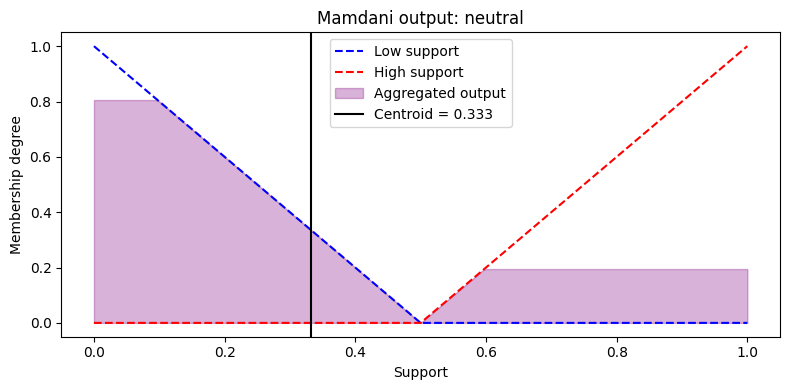

In [ ]:
emotion = example["prediction"]
aggregated = example["aggregated"][emotion]
score = example["scores"][emotion]

plt.figure(figsize=(8, 4))

plt.plot(
    x_support, y_support_low,
    "b--", label="Low support"
)
plt.plot(
    x_support, y_support_high,
    "r--", label="High support"
)

plt.fill_between(
    x_support, 0, aggregated,
    color="purple", alpha=0.3,
    label="Aggregated output"
)

plt.axvline(
    score, color="black",
    label=f"Centroid = {score:.3f}"
)

plt.title(f"Mamdani output: {emotion}")
plt.xlabel("Support")
plt.ylabel("Membership degree")
plt.legend()
plt.tight_layout()
plt.show()


Fuzzy classifier — training diagnostics
Accuracy: 0.393
Balanced accuracy: 0.393
Macro F1: 0.386
              precision    recall  f1-score   support

       angry       0.37      0.44      0.40       112
     disgust       0.30      0.30      0.30       112
      afraid       0.29      0.26      0.27       112
       happy       0.48      0.70      0.57       112
         sad       0.45      0.21      0.28       112
    surprise       0.67      0.54      0.60       112
     neutral       0.26      0.31      0.28       112

    accuracy                           0.39       784
   macro avg       0.40      0.39      0.39       784
weighted avg       0.40      0.39      0.39       784

Decision types:
rule decision                      716
no rule fired; neutral fallback     41
tie                                 27
dtype: int64


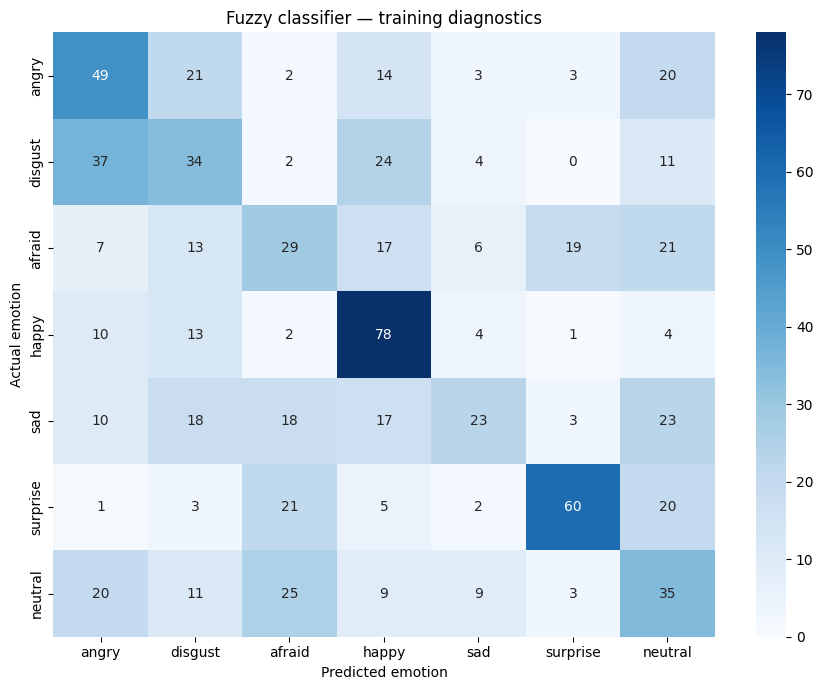

In [ ]:
def predict_fuzzy_batch(feature_matrix):
    details = [
        predict_one_fuzzy(row)
        for row in feature_matrix
    ]

    predictions = np.array([
        result["prediction"] for result in details
    ])

    return predictions, details




def report_results(y_true, predictions, details, title):
    print(title)
    print(f"Accuracy: {accuracy_score(y_true, predictions):.3f}")
    print(
        "Balanced accuracy:",
        f"{balanced_accuracy_score(y_true, predictions):.3f}"
    )
    print(
        "Macro F1:",
        f"{f1_score(y_true, predictions, labels=EMOTIONS, average='macro', zero_division=0):.3f}"
    )

    print(classification_report(
        y_true,
        predictions,
        labels=EMOTIONS,
        zero_division=0
    ))

    statuses = pd.Series([
        result["status"] for result in details
    ])
    print("Decision types:")
    print(statuses.value_counts())

    matrix = confusion_matrix(
        y_true, predictions, labels=EMOTIONS
    )

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=EMOTIONS,
        yticklabels=EMOTIONS
    )
    plt.xlabel("Predicted emotion")
    plt.ylabel("Actual emotion")
    plt.title(title)
    plt.tight_layout()
    plt.show()


train_predictions, train_details = predict_fuzzy_batch(
    geometry_train
)

report_results(
    y_train,
    train_predictions,
    train_details,
    "Fuzzy classifier — training diagnostics"
)


In [ ]:
rows = []

for emotion in EMOTIONS:
    emotion_images = geometry_train[y_train == emotion]

    for rule_number, conditions in enumerate(
        RULES[emotion], start=1
    ):
        for feature, term in conditions:
            degrees = []

            for values in emotion_images:
                memberships = fuzzify_features(values)
                degrees.append(memberships[feature][term])

            degrees = np.asarray(degrees)

            rows.append({
                "emotion": emotion,
                "rule": rule_number,
                "condition": f"{feature} is {term}",
                "average membership": degrees.mean(),
                "fraction zero": (degrees == 0).mean(),
            })

condition_report = pd.DataFrame(rows)

display(condition_report.round(3))


,emotion,rule,condition,average membership,fraction zero
0,angry,1,eyebrow_height is low,0.684,0.116
1,angry,1,brow_separation is low,0.517,0.232
2,angry,1,smile_curvature is low,0.302,0.420
3,angry,2,eyebrow_height is low,0.684,0.116
4,angry,2,eye_opening is low,0.378,0.429
5,angry,2,mouth_opening is low,0.382,0.304
6,disgust,1,eye_opening is low,0.623,0.188
7,disgust,1,mouth_opening is medium,0.496,0.241
8,disgust,1,smile_curvature is medium,0.463,0.205
9,afraid,1,eye_opening is high,0.497,0.268


In [ ]:
# One column per emotion's supporting rule strength
strengths_df = pd.DataFrame([
    result["strengths"]
    for result in train_details
])

strengths_df["actual_emotion"] = y_train

print("Average rule support for each actual emotion:")

display(
    strengths_df.groupby("actual_emotion")[EMOTIONS]
    .mean()
    .round(3)
)


Average rule support for each actual emotion:


,angry,disgust,afraid,happy,sad,surprise,neutral
actual_emotion,,,,,,,
afraid,0.052,0.077,0.189,0.095,0.044,0.090,0.110
angry,0.283,0.164,0.044,0.105,0.019,0.007,0.070
disgust,0.218,0.211,0.021,0.192,0.031,0.000,0.058
happy,0.089,0.108,0.044,0.678,0.016,0.016,0.048
neutral,0.084,0.082,0.174,0.034,0.031,0.014,0.164
sad,0.059,0.111,0.101,0.109,0.119,0.024,0.125
surprise,0.007,0.012,0.122,0.025,0.007,0.344,0.079


In [ ]:
rows = []

for emotion in EMOTIONS:
    own_strengths = strengths_df.loc[
        strengths_df["actual_emotion"] == emotion,
        emotion
    ]

    rows.append({
        "emotion": emotion,
        "fraction with rule firing": (own_strengths > 0).mean(),
        "average rule strength": own_strengths.mean()
    })

display(pd.DataFrame(rows).round(3))


,emotion,fraction with rule firing,average rule strength
0,angry,0.607,0.283
1,disgust,0.491,0.211
2,afraid,0.464,0.189
3,happy,0.839,0.678
4,sad,0.304,0.119
5,surprise,0.741,0.344
6,neutral,0.509,0.164


Fuzzy classifier — held-out KDEF subjects
Accuracy: 0.423
Balanced accuracy: 0.423
Macro F1: 0.408
              precision    recall  f1-score   support

       angry       0.50      0.25      0.33        28
     disgust       0.38      0.50      0.43        28
      afraid       0.29      0.32      0.31        28
       happy       0.56      0.71      0.62        28
         sad       0.42      0.18      0.25        28
    surprise       0.50      0.61      0.55        28
     neutral       0.34      0.39      0.37        28

    accuracy                           0.42       196
   macro avg       0.43      0.42      0.41       196
weighted avg       0.43      0.42      0.41       196

Decision types:
rule decision                      179
no rule fired; neutral fallback     14
tie                                  3
dtype: int64


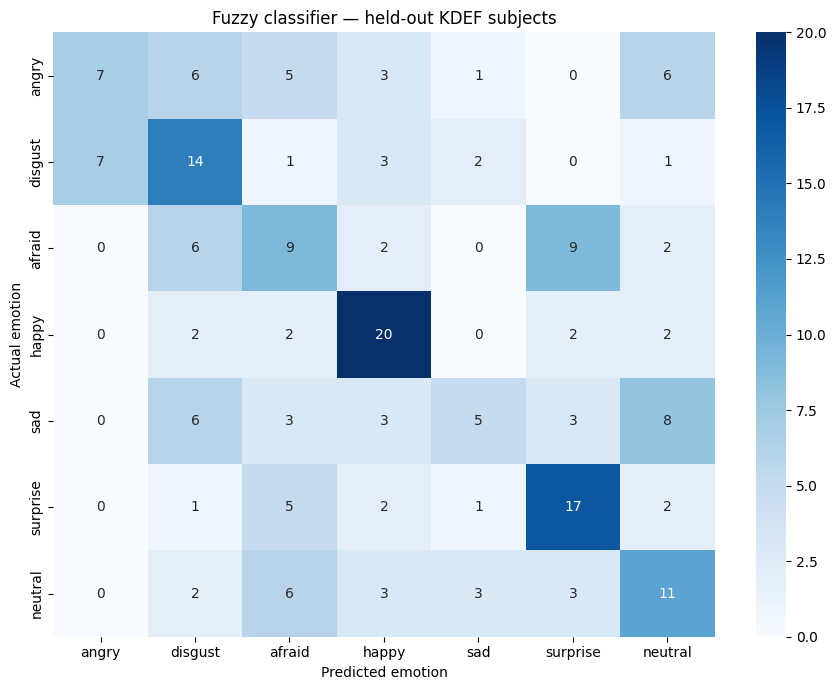

In [ ]:
geometry_test = np.stack([
    geometric_features(points)
    for points in landmarks_test
])

test_predictions, test_details = predict_fuzzy_batch(
    geometry_test
)

report_results(
    y_test,
    test_predictions,
    test_details,
    "Fuzzy classifier — held-out KDEF subjects"
)


In [ ]:
fuzzy_model = {
    "feature_names": FEATURE_NAMES,
    "input_sets": fuzzy_sets,
    "rules": RULES,
    "output_range": x_support,
    "output_low": y_support_low,
    "output_high": y_support_high,
    "defuzzification": "centroid",
    "no_rule_fallback": "neutral",
    "emotion_order": EMOTIONS,
}

with (BASE / "models/fuzzy_kdef_config.pkl").open("wb") as f:
    pickle.dump(fuzzy_model, f)


In [ ]:
emotion_names = np.array([
    "angry",
    "disgust",
    "afraid",
    "happy",
    "sad",
    "surprise",
    "neutral"
])

assert geometry_train.shape[1] == len(FEATURE_NAMES)
assert geometry_test.shape[1] == len(FEATURE_NAMES)

assert np.isfinite(geometry_train).all()
assert np.isfinite(geometry_test).all()

assert np.isin(y_train, emotion_names).all()
assert np.isin(y_test, emotion_names).all()

# Fit scaling using training measurements only
fuzzy_scaler = StandardScaler()

X_fuzzy_train = fuzzy_scaler.fit_transform(geometry_train)
X_fuzzy_test = fuzzy_scaler.transform(geometry_test)

variable_names = np.array(FEATURE_NAMES)

print("Training:", X_fuzzy_train.shape)
print("Test:", X_fuzzy_test.shape)


Training: (784, 8)
Test: (196, 8)


In [ ]:
def build_fuzzy_model(X, targets, number_of_rules=7):

    # Fuzzy clusters in training data
    clusterer = Clusterer(
        x_train=X,
        y_train=targets,
        nr_clus=number_of_rules
    )

    centers, partition_matrix, _ = clusterer.cluster(
        method="fcm"
    )

    # Input membership functions
    antecedent_estimator = AntecedentEstimator(
        x_train=X,
        partition_matrix=partition_matrix
    )

    antecedent_parameters = (
        antecedent_estimator.determineMF()
    )

    # How strongly each training image activates each rule
    strength_calculator = FireStrengthCalculator(
        antecedent_parameters=antecedent_parameters,
        nr_clus=number_of_rules,
        variable_names=variable_names
    )

    firing_strengths = (
        strength_calculator.calculate_fire_strength(data=X)
    )

    # Numerical output of each rule
    consequent_estimator = ConsequentEstimator(
        x_train=X,
        y_train=targets,
        firing_strengths=firing_strengths
    )

    consequent_parameters = consequent_estimator.suglms()

    # Executable Sugeno system
    builder = SugenoFISBuilder(
        antecedent_sets=antecedent_parameters,
        consequent_parameters=consequent_parameters,
        variable_names=variable_names,
        save_simpful_code=False
    )

    return builder.get_model(), antecedent_parameters


In [ ]:
NUMBER_OF_RULES = 7

learned_fuzzy_models = {}
learned_memberships = {}

for emotion in emotion_names:
    print("\nTraining model for:", emotion)

    binary_targets = (
        y_train == emotion
    ).astype(float)

    np.random.seed(42)

    fuzzy_model, membership_parameters = build_fuzzy_model(
        X_fuzzy_train,
        binary_targets,
        number_of_rules=NUMBER_OF_RULES
    )

    learned_fuzzy_models[emotion] = fuzzy_model
    learned_memberships[emotion] = membership_parameters

print("\nAll seven models trained.")



Training model for: angry
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: disgust
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: afraid
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: happy
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: sad
['mouth_opening' 'mouth_width' 'eye_open

In [ ]:
def predict_learned_fuzzy(X):
    score_columns = []

    for emotion in emotion_names:
        tester = SugenoFISTester(
            model=learned_fuzzy_models[emotion],
            test_data=X,
            variable_names=variable_names
        )

        output_values, _ = tester.predict()

        score_columns.append(
            np.asarray(output_values).reshape(-1)
        )
        
    scores = np.column_stack(score_columns)

    if not np.isfinite(scores).all():
        raise ValueError(
            "Invalid model outputs. Inspect the learned memberships."
        )

    winning_columns = np.argmax(scores, axis=1)
    predictions = emotion_names[winning_columns]

    return predictions, scores


In [ ]:
learned_train_predictions, learned_train_scores = (
    predict_learned_fuzzy(X_fuzzy_train)
)

print("Training accuracy:",
      accuracy_score(y_train, learned_train_predictions))

print("Training macro F1:",
      f1_score(
          y_train,
          learned_train_predictions,
          labels=emotion_names,
          average="macro",
          zero_division=0
      ))


Training accuracy: 0.5127551020408163
Training macro F1: 0.48041905559780546


In [ ]:
learned_test_predictions, learned_test_scores = (
    predict_learned_fuzzy(X_fuzzy_test)
)

learned_result = {
    "Model": "pyFUME — seven binary Sugeno models",
    "Accuracy": accuracy_score(
        y_test, learned_test_predictions
    ),
    "Balanced accuracy": balanced_accuracy_score(
        y_test, learned_test_predictions
    ),
    "Macro F1": f1_score(
        y_test,
        learned_test_predictions,
        labels=emotion_names,
        average="macro",
        zero_division=0
    )
}

display(pd.DataFrame([learned_result]).round(3))

print(classification_report(
    y_test,
    learned_test_predictions,
    labels=emotion_names,
    zero_division=0
))


,Model,Accuracy,Balanced accuracy,Macro F1
0,pyFUME — seven binary Sugeno models,0.485,0.485,0.454


              precision    recall  f1-score   support

       angry       0.41      0.50      0.45        28
     disgust       0.45      0.36      0.40        28
      afraid       0.40      0.14      0.21        28
       happy       0.64      0.89      0.75        28
         sad       0.47      0.29      0.36        28
    surprise       0.43      0.82      0.57        28
     neutral       0.52      0.39      0.45        28

    accuracy                           0.48       196
   macro avg       0.48      0.48      0.45       196
weighted avg       0.48      0.48      0.45       196



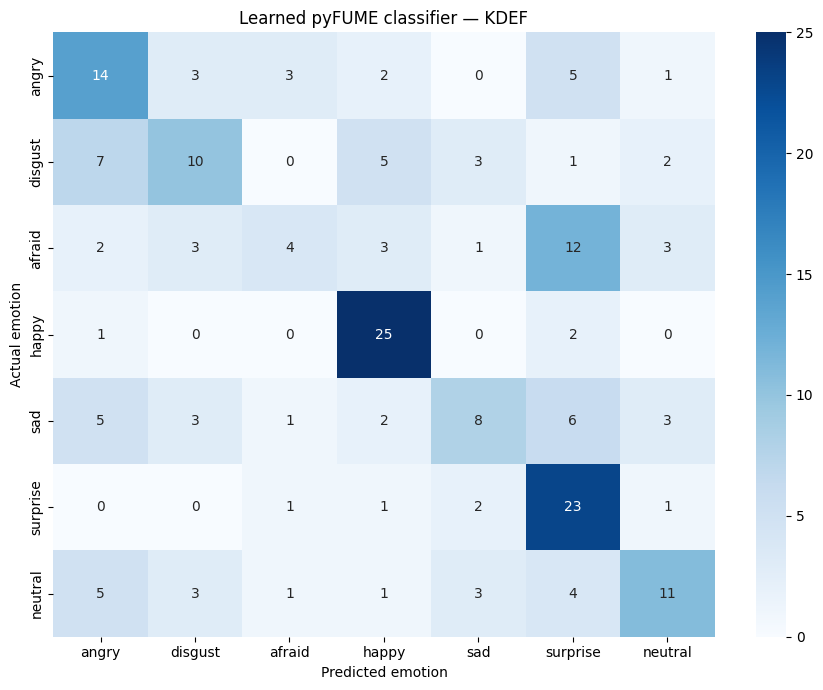

In [ ]:
matrix = confusion_matrix(
    y_test,
    learned_test_predictions,
    labels=emotion_names
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.title("Learned pyFUME classifier — KDEF")
plt.tight_layout()
plt.show()


In [ ]:
with (BASE / "auxFiles/kdef_subject_split.pkl").open("rb") as f:
    subject_split = pickle.load(f)

original_train_subjects = set(subject_split["train_subjects"])
original_test_subjects = set(subject_split["test_subjects"])

emotion_codes = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

recovered_subjects = []

for image_path in (BASE / "data/KDEF").rglob("*.JPG"):
    filename = image_path.stem

    subject = filename[1:4]
    emotion_code = filename[4:6]
    pose = filename[6:]

    if subject not in original_train_subjects:
        continue

    if emotion_code not in emotion_codes or pose != "S":
        continue

    position = len(recovered_subjects)

    if position >= len(X_train):
        raise ValueError("More source images than saved training images.")

    recovered_image = preprocess_kdef_image(str(image_path))

    correct_emotion = (
        emotion_codes[emotion_code] == y_train[position]
    )

    correct_image = np.allclose(
        recovered_image,
        X_train[position],
        rtol=0,
        atol=1e-6
    )

    if not correct_emotion or not correct_image:
        raise ValueError(
            f"Image order could not be verified at {image_path.name}. "
            "Stop here: do not create the validation split."
        )

    recovered_subjects.append(subject)

subjects_train = np.asarray(recovered_subjects)

assert len(subjects_train) == len(X_train) == len(geometry_train)
assert set(subjects_train).isdisjoint(original_test_subjects)

print("Subject IDs verified for", len(subjects_train), "training images.")
print("Number of training subjects:", len(np.unique(subjects_train)))


Subject IDs verified for 784 training images.
Number of training subjects: 56


In [ ]:
subject_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

anfis_train_indices, anfis_valid_indices = next(
    subject_splitter.split(
        geometry_train,
        y_train,
        groups=subjects_train
    )
)

# Reuse the existing geometric measurements.
anfis_train_features = geometry_train[anfis_train_indices]
anfis_valid_features = geometry_train[anfis_valid_indices]

anfis_y_train = y_train[anfis_train_indices]
anfis_y_valid = y_train[anfis_valid_indices]

training_people = set(subjects_train[anfis_train_indices])
validation_people = set(subjects_train[anfis_valid_indices])

assert training_people.isdisjoint(validation_people)

assert set(anfis_y_train) == set(emotion_names)
assert set(anfis_y_valid) == set(emotion_names)

print("Training images:", len(anfis_y_train))
print("Validation images:", len(anfis_y_valid))
print("Shared subjects:", training_people & validation_people)


Training images: 616
Validation images: 168
Shared subjects: set()


In [ ]:
anfis_scaler = StandardScaler()

anfis_X_train = anfis_scaler.fit_transform(
    anfis_train_features
)

anfis_X_valid = anfis_scaler.transform(
    anfis_valid_features
)

assert np.isfinite(anfis_X_train).all()
assert np.isfinite(anfis_X_valid).all()

print("ANFIS training shape:", anfis_X_train.shape)
print("ANFIS validation shape:", anfis_X_valid.shape)


ANFIS training shape: (616, 8)
ANFIS validation shape: (168, 8)


In [ ]:
class ANFIS:
    def __init__(self, n_clusters, X):

        self.n_clusters = n_clusters
        self.n_features = X.shape[1]

        kmeans = KMeans(
            n_clusters=n_clusters,
            random_state=42,
            n_init=10
        ).fit(X)

        self.centers = kmeans.cluster_centers_.copy()

        self.stds = np.ones(
            (n_clusters, self.n_features),
            dtype=float
        )

        self.w = None

    def _membership(self, X):
        differences = X[:, None, :] - self.centers[None, :, :]

        log_strengths = -np.sum(
            differences ** 2 / (2 * self.stds[None, :, :] ** 2),
            axis=2
        )

        log_strengths -= log_strengths.max(
            axis=1,
            keepdims=True
        )

        strengths = np.exp(log_strengths)

        return strengths / strengths.sum(
            axis=1,
            keepdims=True
        )

    def fit(
        self,
        X,
        y,
        Xv,
        yv,
        epochs=100,
        lr=0.001,
        patience=15
    ):
        best_validation_mse = np.inf
        best_parameters = None
        waiting = 0

        self.history_ = []

        for epoch in range(epochs):
            memberships = self._membership(X)

            self.w = np.linalg.lstsq(
                memberships,
                y,
                rcond=None
            )[0]

            train_predictions = memberships @ self.w
            valid_predictions = self.predict(Xv)

            train_mse = mean_squared_error(
                y, train_predictions
            )
            valid_mse = mean_squared_error(
                yv, valid_predictions
            )

            self.history_.append({
                "epoch": epoch + 1,
                "training_mse": train_mse,
                "validation_mse": valid_mse
            })

            if valid_mse < best_validation_mse:
                best_validation_mse = valid_mse
                self.best_epoch_ = epoch + 1

                best_parameters = (
                    self.centers.copy(),
                    self.stds.copy(),
                    self.w.copy()
                )

                waiting = 0
            else:
                waiting += 1

            if epoch == 0 or (epoch + 1) % 10 == 0:
                print(
                    f"Epoch {epoch + 1}: "
                    f"training MSE = {train_mse:.4f}, "
                    f"validation MSE = {valid_mse:.4f}",
                    flush=True
                )

            if waiting >= patience:
                print("Early stopping.", flush=True)
                break

            if epoch == epochs - 1:
                break

            differences = (
                X[:, None, :] - self.centers[None, :, :]
            )

            errors = train_predictions - y

            sensitivity = memberships * (
                self.w[None, :] - train_predictions[:, None]
            )

            common = (
                2 * errors[:, None] * sensitivity
            )[:, :, None]

            gradient_centers = np.mean(
                common * differences
                / self.stds[None, :, :] ** 2,
                axis=0
            )

            gradient_widths = np.mean(
                common * differences ** 2
                / self.stds[None, :, :] ** 3,
                axis=0
            )

            gradient_centers = np.clip(
                gradient_centers, -1, 1
            )
            gradient_widths = np.clip(
                gradient_widths, -0.5, 0.5
            )

            self.centers -= lr * gradient_centers

            self.stds = np.maximum(
                self.stds - lr * gradient_widths,
                0.1
            )

        self.centers, self.stds, self.w = best_parameters
        self.best_validation_mse_ = best_validation_mse

        return self

    def predict(self, X):
        if self.w is None:
            raise ValueError("Train the model before predicting.")

        memberships = self._membership(X)

        return memberships @ self.w


In [ ]:
NUMBER_OF_ANFIS_RULES = 7

anfis_models = {}

for emotion in emotion_names:
    print(f"\nTraining ANFIS for: {emotion}")

    # 1 = this emotion; 0 = another emotion.
    binary_train = (anfis_y_train == emotion).astype(float)
    binary_valid = (anfis_y_valid == emotion).astype(float)

    model = ANFIS(
        n_clusters=NUMBER_OF_ANFIS_RULES,
        X=anfis_X_train
    )

    model.fit(
        anfis_X_train,
        binary_train,
        anfis_X_valid,
        binary_valid,
        epochs=100,
        lr=0.001,
        patience=15
    )

    anfis_models[emotion] = model

    print("Best epoch:", model.best_epoch_)



Training ANFIS for: angry
Epoch 1: training MSE = 0.1009, validation MSE = 0.0913
Epoch 10: training MSE = 0.1009, validation MSE = 0.0913
Epoch 20: training MSE = 0.1009, validation MSE = 0.0913
Epoch 30: training MSE = 0.1009, validation MSE = 0.0913
Epoch 40: training MSE = 0.1009, validation MSE = 0.0913
Epoch 50: training MSE = 0.1009, validation MSE = 0.0913
Epoch 60: training MSE = 0.1009, validation MSE = 0.0913
Epoch 70: training MSE = 0.1009, validation MSE = 0.0913
Epoch 80: training MSE = 0.1009, validation MSE = 0.0913
Epoch 90: training MSE = 0.1009, validation MSE = 0.0913
Epoch 100: training MSE = 0.1009, validation MSE = 0.0913
Best epoch: 100

Training ANFIS for: disgust
Epoch 1: training MSE = 0.1070, validation MSE = 0.1054
Epoch 10: training MSE = 0.1070, validation MSE = 0.1054
Epoch 20: training MSE = 0.1070, validation MSE = 0.1054
Epoch 30: training MSE = 0.1070, validation MSE = 0.1054
Epoch 40: training MSE = 0.1070, validation MSE = 0.1054
Epoch 50: trainin

In [ ]:
def predict_anfis_emotions(X):
    score_columns = []

    for emotion in emotion_names:
        model = anfis_models[emotion]
        score_columns.append(model.predict(X))

    scores = np.column_stack(score_columns)

    if not np.isfinite(scores).all():
        raise ValueError("ANFIS produced invalid scores.")

    winning_columns = np.argmax(scores, axis=1)
    predictions = emotion_names[winning_columns]

    return predictions, scores


In [ ]:
anfis_results = []

datasets = {
    "Training": (anfis_X_train, anfis_y_train),
    "Validation": (anfis_X_valid, anfis_y_valid)
}

for name, (features, labels) in datasets.items():
    predictions, _ = predict_anfis_emotions(features)

    anfis_results.append({
        "Dataset": name,
        "Accuracy": accuracy_score(labels, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            labels, predictions
        ),
        "Macro F1": f1_score(
            labels,
            predictions,
            labels=emotion_names,
            average="macro",
            zero_division=0
        )
    })

display(pd.DataFrame(anfis_results).round(3))

anfis_valid_predictions, _ = predict_anfis_emotions(
    anfis_X_valid
)

print(classification_report(
    anfis_y_valid,
    anfis_valid_predictions,
    labels=emotion_names,
    zero_division=0
))


,Dataset,Accuracy,Balanced accuracy,Macro F1
0,Training,0.456,0.456,0.397
1,Validation,0.446,0.446,0.384


              precision    recall  f1-score   support

       angry       0.48      0.62      0.55        24
     disgust       0.38      0.38      0.38        24
      afraid       0.00      0.00      0.00        24
       happy       0.76      0.67      0.71        24
         sad       0.00      0.00      0.00        24
    surprise       0.59      0.79      0.68        24
     neutral       0.27      0.67      0.38        24

    accuracy                           0.45       168
   macro avg       0.35      0.45      0.38       168
weighted avg       0.35      0.45      0.38       168



In [ ]:
anfis_X_test = anfis_scaler.transform(geometry_test)

assert np.isfinite(anfis_X_test).all()
assert len(anfis_X_test) == len(y_test)

print("Test feature shape:", anfis_X_test.shape)


Test feature shape: (196, 8)


In [ ]:
anfis_test_predictions, anfis_test_scores = (
    predict_anfis_emotions(anfis_X_test)
)


In [ ]:
anfis_test_result = {
    "Model": "ANFIS — trained on 616 images",

    "Accuracy": accuracy_score(
        y_test, anfis_test_predictions
    ),

    "Balanced accuracy": balanced_accuracy_score(
        y_test, anfis_test_predictions
    ),

    "Macro F1": f1_score(
        y_test,
        anfis_test_predictions,
        labels=emotion_names,
        average="macro",
        zero_division=0
    )
}

display(pd.DataFrame([anfis_test_result]).round(3))

print(classification_report(
    y_test,
    anfis_test_predictions,
    labels=emotion_names,
    zero_division=0
))


,Model,Accuracy,Balanced accuracy,Macro F1
0,ANFIS — trained on 616 images,0.449,0.449,0.383


              precision    recall  f1-score   support

       angry       0.42      0.46      0.44        28
     disgust       0.37      0.39      0.38        28
      afraid       0.00      0.00      0.00        28
       happy       0.80      0.71      0.75        28
         sad       1.00      0.04      0.07        28
    surprise       0.43      0.86      0.57        28
     neutral       0.36      0.68      0.47        28

    accuracy                           0.45       196
   macro avg       0.48      0.45      0.38       196
weighted avg       0.48      0.45      0.38       196



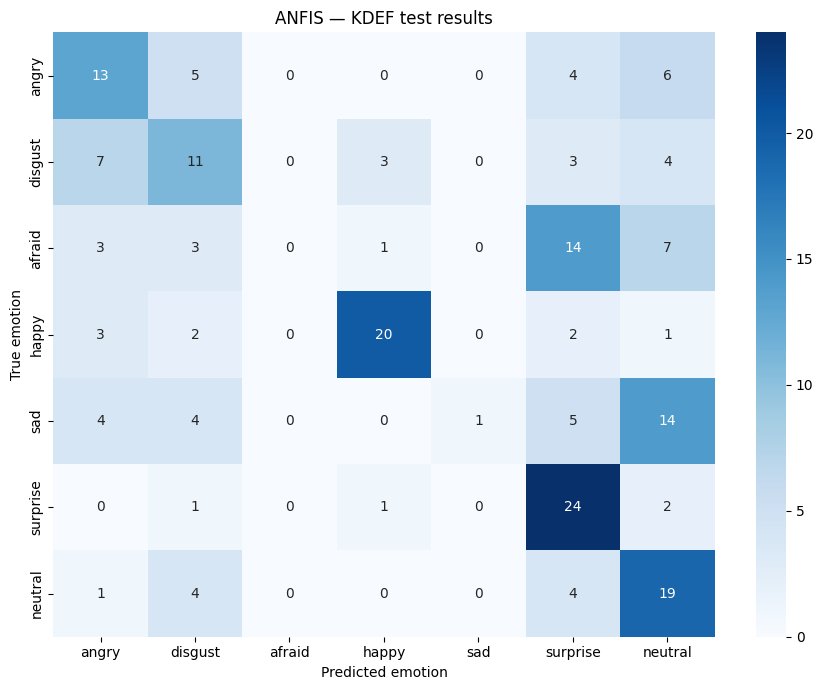

In [ ]:
anfis_matrix = confusion_matrix(
    y_test,
    anfis_test_predictions,
    labels=emotion_names
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    anfis_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.xlabel("Predicted emotion")
plt.ylabel("True emotion")
plt.title("ANFIS — KDEF test results")
plt.tight_layout()
plt.show()


# Task 5 - Improving FER2013 emotion recognition

The aim is to improve FER2013 predictions using class balancing, augmentation, tuning and feature selection. Image quality is also inspected.

Training is used to fit models. PublicTest is used to compare settings. PrivateTest is reserved for final evaluation. Results below use PublicTest unless stated otherwise.

## 1. Imports

The next cell loads the tools for image processing, model training and evaluation.

## 2. Load Training and PublicTest

The following cells load the images and emotion labels. They check the labels and count images in each class.

**Result:** Training contains 28,709 images. PublicTest contains 3,589. Happy has 7,215 training images, while Disgust has 436. This imbalance motivates class weighting.

In [ ]:
BASE = Path(".")

train_df = pd.read_csv(
    BASE / "data/fer2013_train.csv"
)

valid_df = pd.read_csv(
    BASE / "data/fer2013_validation.csv"
)

class_names = [
    "Angry", "Disgust", "Fear", "Happy",
    "Sad", "Surprise", "Neutral"
]

y_train = train_df["emotion"].to_numpy()
y_valid = valid_df["emotion"].to_numpy()

print("Training images:", len(train_df))
print("Validation images:", len(valid_df))


Training images: 28709
Validation images: 3589


In [ ]:
classes = np.arange(7)
assert np.isin(y_train, classes).all()
assert np.isin(y_valid, classes).all()

# These names refer to the same training rows.
trai_df = train_df
labelsTrain = y_train


,Emotion,Training images
0,Angry,3995
1,Disgust,436
2,Fear,4097
3,Happy,7215
4,Sad,4830
5,Surprise,3171
6,Neutral,4965


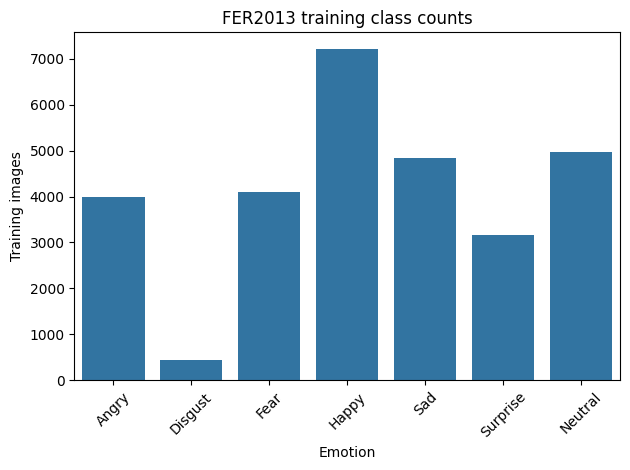

In [ ]:
class_counts = (
    train_df["emotion"]
    .value_counts()
    .sort_index()
)

count_table = pd.DataFrame({
    "Emotion": class_names,
    "Training images": class_counts.reindex(
        range(7), fill_value=0
    ).to_numpy()
})

display(count_table)

sns.barplot(
    data=count_table,
    x="Emotion",
    y="Training images"
)

plt.xticks(rotation=45)
plt.title("FER2013 training class counts")
plt.tight_layout()
plt.show()


## 3. Inspect training image quality

The following cells measure average brightness and pixel variation. They display the 20 darkest training images and count completely black images. Low brightness alone is not a reason to remove an image.

Mean brightness <= 5: 11 images
Mean brightness <= 10: 13 images
Mean brightness <= 15: 16 images
Mean brightness <= 20: 19 images
Mean brightness <= 25: 23 images
Mean brightness <= 30: 32 images
Standard deviation <= 2: 12 images
Standard deviation <= 3: 12 images
Standard deviation <= 5: 12 images
Standard deviation <= 8: 12 images
Standard deviation <= 10: 13 images
Number of training images: 28709
Images with mean brightness <= 5: 11
Images with standard deviation <= 2: 12


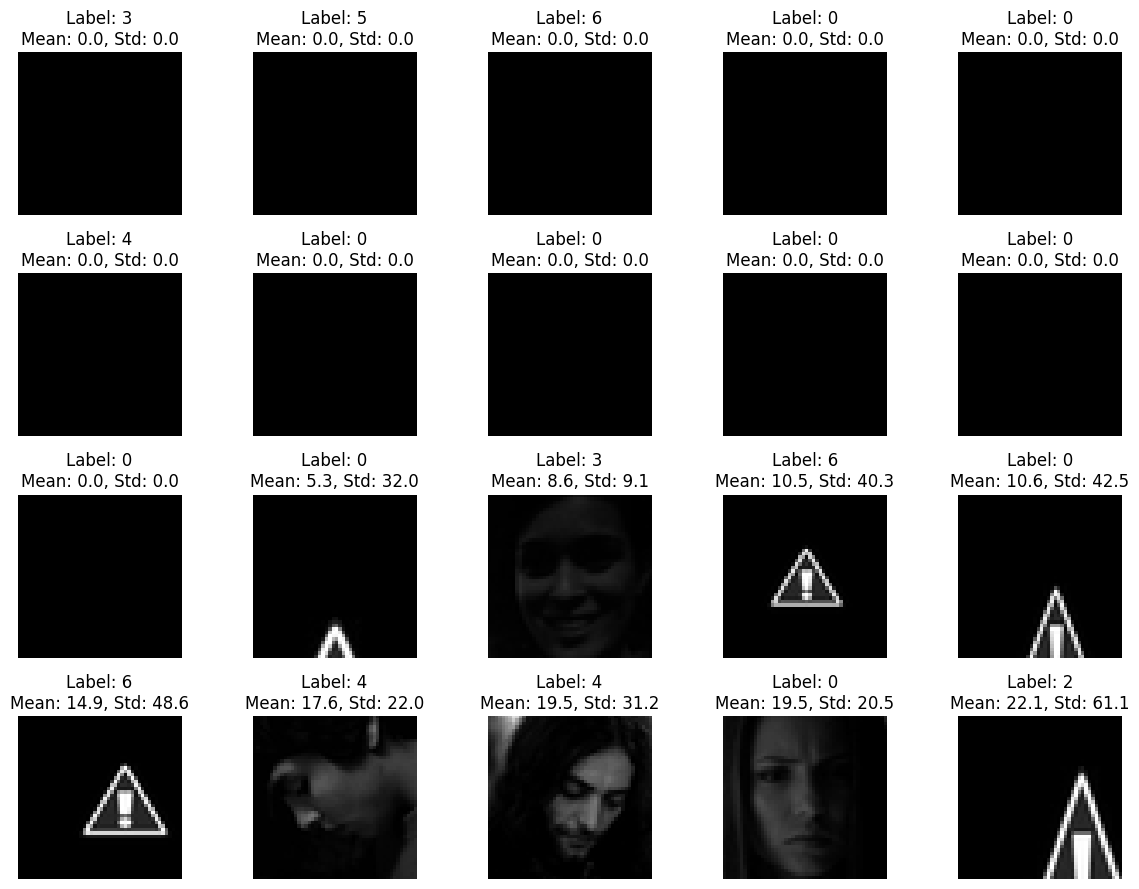

In [ ]:
RUN_IMAGE_INSPECTION = True

if RUN_IMAGE_INSPECTION:


    train_images = np.array([
        np.fromstring(pixels, sep=' ').reshape(48, 48)
        for pixels in trai_df['pixels']
    ])

    mean_brightness = train_images.mean(axis=(1, 2))
    std_brightness = train_images.std(axis=(1, 2))

    for threshold in [5, 10, 15, 20, 25, 30]:
        count = np.sum(mean_brightness <= threshold)
        print(f"Mean brightness <= {threshold}: {count} images")

    for threshold in [2, 3, 5, 8, 10]:
        count = np.sum(std_brightness <= threshold)
        print(f"Standard deviation <= {threshold}: {count} images")

    print("Number of training images:", len(train_images))
    print("Images with mean brightness <= 5:",
          np.sum(mean_brightness <= 5))
    print("Images with standard deviation <= 2:",
          np.sum(std_brightness <= 2))

    darkest_indices = np.argsort(mean_brightness)[:20]

    fig, axes = plt.subplots(4, 5, figsize=(12, 9))

    for ax, idx in zip(axes.flat, darkest_indices):
        ax.imshow(train_images[idx], cmap="gray", vmin=0, vmax=255)
        ax.set_title(
            f"Label: {trai_df.iloc[idx]['emotion']}\n"
            f"Mean: {mean_brightness[idx]:.1f}, "
            f"Std: {std_brightness[idx]:.1f}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print('Image inspection skipped; previous outputs remain available.')


In [ ]:
if RUN_IMAGE_INSPECTION:

    black_mask = (train_images == 0).all(axis=(1, 2))

    print("Completely black images:", black_mask.sum())

    print("\nEmotion labels of black images:")
    print(trai_df.loc[black_mask, "emotion"].value_counts().sort_index())


Completely black images: 11

Emotion labels of black images:
0    7
3    1
4    1
5    1
6    1
Name: emotion, dtype: int64


**Result:** 11 training images are completely black. They contain no facial information. They were retained, so this inspection does not demonstrate a performance improvement.

## 4. Extract HOG features

The function converts each pixel string into a 48 x 48 image. It then measures local edges with HOG.

In [ ]:
RUN_HOG_EXTRACTION = True

def extract_hog_from_dataframe(dataframe):
    """Return one HOG feature vector per image."""
    feature_rows = []

    for pixels in dataframe["pixels"]:
        image = np.fromstring(
            pixels,
            sep=" ",
            dtype=np.uint8
        ).reshape(48, 48)

        features = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        feature_rows.append(features)

    return np.asarray(feature_rows, dtype=np.float32)

if RUN_HOG_EXTRACTION:
    X_train_hog = extract_hog_from_dataframe(train_df)

    X_valid_hog = extract_hog_from_dataframe(valid_df)

    print("Training features:", X_train_hog.shape)

    print("Validation features:", X_valid_hog.shape)
else:
    print("HOG extraction skipped; reuse features already in this kernel.")


Training features: (28709, 900)
Validation features: (3589, 900)


In [ ]:
assert X_train_hog.shape == (len(y_train), 900)
assert X_valid_hog.shape == (len(y_valid), 900)
assert np.isfinite(X_train_hog).all()
assert np.isfinite(X_valid_hog).all()

hog_feats = X_train_hog
hog_valid = X_valid_hog


## 5. Evaluation functions and class weights

The following cells calculate class weights and define common evaluation functions. Macro F1 gives equal importance to each emotion. Balanced accuracy is the average recall across emotions.

In [ ]:
classes = np.arange(7)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

weight_table = pd.DataFrame({
    "Emotion": class_names,
    "Weight": weights
})

display(weight_table.round(3))


,Emotion,Weight
0,Angry,1.027
1,Disgust,9.407
2,Fear,1.001
3,Happy,0.568
4,Sad,0.849
5,Surprise,1.293
6,Neutral,0.826


In [ ]:
classes = np.unique(y_train)

full_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

selected_weights = {}

# The exponent softens the full balanced weights.
for label, weight in zip(classes, full_weights):
    selected_weights[int(label)] = float(weight ** 0.75)

print("Class weights:", selected_weights)


Class weights: {0: 1.0198878809708158, 1: 5.3712473448255755, 2: 1.0007844436428528, 3: 0.6546554193397086, 4: 0.8845648359477872, 5: 1.2128101905683368, 6: 0.8664641118338571}


In [ ]:
def create_forest(depth=11, minimum_leaf=1):
    """Create a forest with the selected class weights."""
    return RandomForestClassifier(
        n_estimators=300,
        max_depth=depth,
        min_samples_leaf=minimum_leaf,
        max_features="sqrt",
        criterion="entropy",
        class_weight=selected_weights,
        random_state=42,
        n_jobs=-1
    )

def evaluate_predictions(name, predictions):
    """Calculate validation scores for one experiment."""
    return {
        "Experiment": name,
        "Accuracy": accuracy_score(
            y_valid, predictions
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_valid, predictions
        ),
        "Macro F1": f1_score(
            y_valid,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )
    }


In [ ]:
def record_result(name, model, predictions=None, columns=None):
    """Add a model and its scores to the comparison."""
    features = X_valid_hog if columns is None else X_valid_hog[:, columns]
    if predictions is None:
        predictions = model.predict(features)
    result = evaluate_predictions(name, predictions)
    validation_results[:] = [
        row for row in validation_results if row["Experiment"] != name
    ]
    validation_results.append(result)
    candidate_models[name] = (model, columns)
    return result

validation_results = []

candidate_models = {}


## 6. Random Forest baseline and class balancing

The following cells train two forests with the same settings: one uses no class weights and the other uses balanced weights. Their validation scores and confusion matrices show the effect of weighting.

In [ ]:
RUN_BASELINE_TRAINING = True

if RUN_BASELINE_TRAINING:
    baseline_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=11,
        max_features="sqrt",
        criterion="entropy",
        random_state=42,
        n_jobs=-1,
        class_weight=None
    )

    baseline_model.fit(X_train_hog, y_train)
    print("Baseline model trained.")
else:
    print('Baseline training skipped; reuse the trained model in this kernel.')

RUN_BALANCED_TRAINING = True

if RUN_BALANCED_TRAINING:
    balanced_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=11,
        max_features="sqrt",
        criterion="entropy",
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    balanced_model.fit(X_train_hog, y_train)
    print("Balanced model trained.")
else:
    print('Balanced training skipped; reuse the trained model in this kernel.')


Baseline model trained.
Balanced model trained.


In [ ]:
baseline_predictions = baseline_model.predict(X_valid_hog)

balanced_predictions = balanced_model.predict(X_valid_hog)

predictions = {
    "Baseline": baseline_predictions,
    "Balanced weights": balanced_predictions
}

results = []

for name, predicted_labels in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_valid, predicted_labels
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_valid, predicted_labels
        ),
        "Macro F1": f1_score(
            y_valid,
            predicted_labels,
            labels=range(7),
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))


,Model,Accuracy,Balanced accuracy,Macro F1
0,Baseline,0.452,0.375,0.388
1,Balanced weights,0.469,0.432,0.439


In [ ]:
for name, predicted_labels in predictions.items():
    print("\n", name)

    print(classification_report(
        y_valid,
        predicted_labels,
        labels=range(7),
        target_names=class_names,
        zero_division=0
    ))



 Baseline
              precision    recall  f1-score   support

       Angry       0.48      0.12      0.19       467
     Disgust       1.00      0.20      0.33        56
        Fear       0.55      0.18      0.27       496
       Happy       0.42      0.91      0.58       895
         Sad       0.42      0.25      0.31       653
    Surprise       0.76      0.53      0.63       415
     Neutral       0.38      0.44      0.41       607

    accuracy                           0.45      3589
   macro avg       0.57      0.38      0.39      3589
weighted avg       0.49      0.45      0.41      3589


 Balanced weights
              precision    recall  f1-score   support

       Angry       0.41      0.28      0.33       467
     Disgust       0.73      0.34      0.46        56
        Fear       0.40      0.23      0.29       496
       Happy       0.51      0.77      0.62       895
         Sad       0.41      0.32      0.36       653
    Surprise       0.56      0.70      0.62     

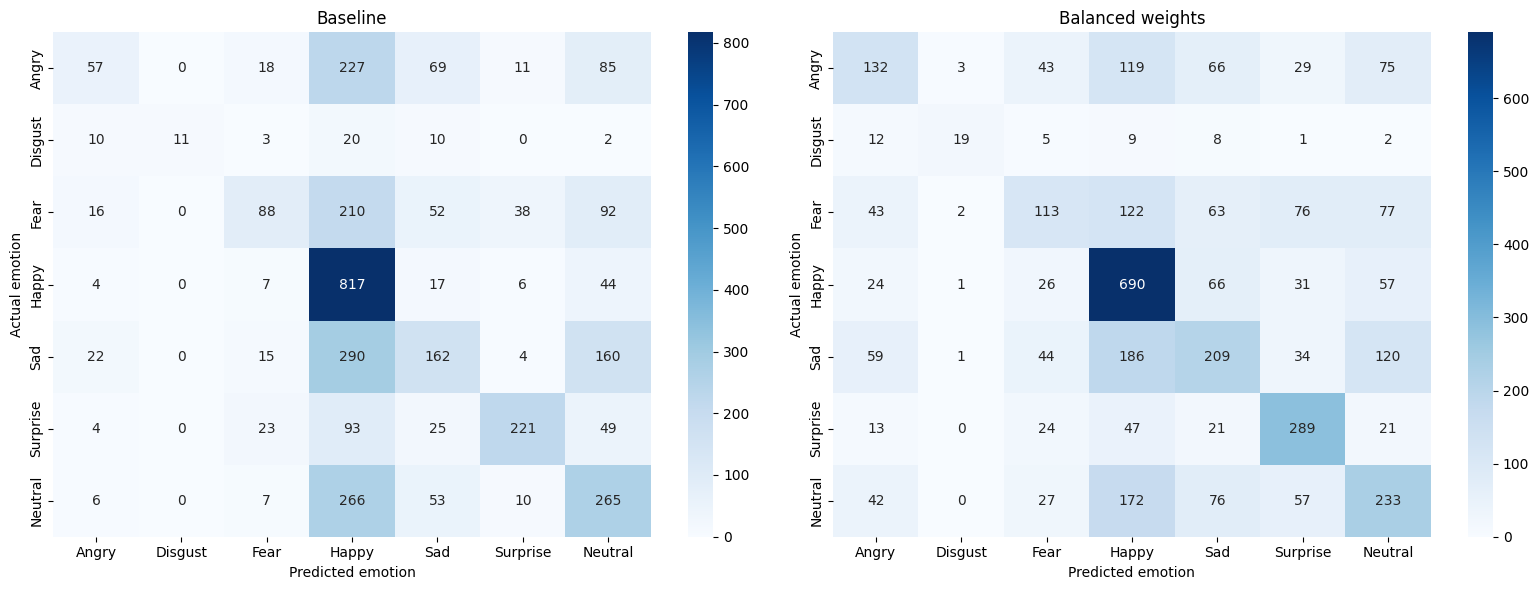

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, predicted_labels) in zip(
    axes, predictions.items()
):
    matrix = confusion_matrix(
        y_valid,
        predicted_labels,
        labels=range(7)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted emotion")
    ax.set_ylabel("Actual emotion")

plt.tight_layout()
plt.show()


In [ ]:
record_result("RF baseline", baseline_model, baseline_predictions)
record_result("RF balanced weights", balanced_model, balanced_predictions)


{'Experiment': 'RF balanced weights',
 'Accuracy': 0.4694901086653664,
 'Balanced accuracy': 0.43157358349672004,
 'Macro F1': 0.4391633873999357}

### Optional weight-strength search

The next cell compares weight exponents of 0.5, 0.75 and 1.25. It is skipped in the recorded run. The following forest uses the fixed exponent 0.75.


In [ ]:
RUN_WEIGHT_SEARCH = False

if RUN_WEIGHT_SEARCH:

    classes = np.unique(y_train)

    full_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )

    extra_results = []

    for strength in [0.5, 0.75, 1.25]:
        custom_weights = {
            int(label): float(weight ** strength)
            for label, weight in zip(classes, full_weights)
        }

        model = clone(baseline_model)
        model.set_params(class_weight=custom_weights)

        model.fit(X_train_hog, y_train)
        predicted = model.predict(X_valid_hog)

        record_result(f"RF weight strength {strength}", model, predicted)

        extra_results.append({
            "Model": f"Weight strength {strength}",
            "Accuracy": accuracy_score(y_valid, predicted),
            "Balanced accuracy": balanced_accuracy_score(
                y_valid, predicted
            ),
            "Macro F1": f1_score(
                y_valid,
                predicted,
                labels=classes,
                average="macro",
                zero_division=0
            )
        })

        print(f"Finished strength {strength}")

    comparison_results = pd.concat(
        [results_df, pd.DataFrame(extra_results)],
        ignore_index=True
    )

    display(
        comparison_results
        .sort_values("Macro F1", ascending=False)
        .round(3)
    )

else:
    print("Weight search skipped. Selected strength: 0.75")


Weight search skipped. Selected strength: 0.75


In [ ]:
RUN_REFERENCE_TRAINING = True

if RUN_REFERENCE_TRAINING:
    reference_model = create_forest(
        depth=11,
        minimum_leaf=1
    )

    reference_model.fit(X_train_hog, y_train)
else:
    print('Reference training skipped; reuse the trained model in this kernel.')

reference_predictions = reference_model.predict(
    X_valid_hog
)

reference_result = evaluate_predictions(
    "Reference: 0.75 weights, all features",
    reference_predictions
)

display(pd.DataFrame([reference_result]).round(3))


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"Reference: 0.75 weights, all features",0.461,0.408,0.422


In [ ]:
record_result("RF 0.75 weights, depth 11", reference_model, reference_predictions)


{'Experiment': 'RF 0.75 weights, depth 11',
 'Accuracy': 0.46140986347171914,
 'Balanced accuracy': 0.40767311791196964,
 'Macro F1': 0.42241852849821176}

## 7. Data augmentation

The following cells flip, rotate, shift and slightly change the brightness of training images. They extract HOG features from the new images and train an unweighted forest. Validation images are unchanged.

In [ ]:
def augment_image(image, rng):
    """Flip, rotate, shift and adjust image brightness."""
    modified = image.copy()

    if rng.random() < 0.5:
        modified = cv2.flip(modified, 1)

    angle = rng.uniform(-8, 8)
    shift_x = rng.uniform(-2, 2)
    shift_y = rng.uniform(-2, 2)

    height, width = modified.shape

    # Keep changes small to preserve the expression.
    matrix = cv2.getRotationMatrix2D(
        ((width - 1) / 2, (height - 1) / 2),
        angle,
        1.0
    )

    matrix[0, 2] += shift_x
    matrix[1, 2] += shift_y

    modified = cv2.warpAffine(
        modified,
        matrix,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT_101
    )

    # Keep pixel values between 0 and 255.
    brightness = rng.uniform(0.9, 1.1)

    modified = np.clip(
        modified.astype(np.float32) * brightness,
        0, 255
    ).astype(np.uint8)

    return modified


In [ ]:
y_train = np.asarray(y_train)

assert np.array_equal(
    train_df["emotion"].to_numpy(),
    y_train
)

assert len(X_train_hog) == len(y_train)

counts = (
    train_df["emotion"]
    .value_counts()
    .sort_index()
)

target_size = int(np.median(counts.to_numpy()))

plan = []

for label, original_count in counts.items():

    # Keep every original image. Limit each class to four times its size.
    final_count = max(
        original_count,
        min(target_size, 4 * original_count)
    )

    plan.append({
        "Label": int(label),
        "Emotion": class_names[int(label)],
        "Original": int(original_count),
        "Add": int(final_count - original_count),
        "Final": int(final_count)
    })

augmentation_plan = pd.DataFrame(plan)

display(augmentation_plan)


,Label,Emotion,Original,Add,Final
0,0,Angry,3995,102,4097
1,1,Disgust,436,1308,1744
2,2,Fear,4097,0,4097
3,3,Happy,7215,0,7215
4,4,Sad,4830,0,4830
5,5,Surprise,3171,926,4097
6,6,Neutral,4965,0,4965


In [ ]:
RUN_AUGMENTATION_GENERATION = True

if RUN_AUGMENTATION_GENERATION:
    rng = np.random.default_rng(42)

    extra_images = []
    extra_labels = []
    source_indices = []

    for _, item in augmentation_plan.iterrows():
        label = int(item["Label"])
        number_to_add = int(item["Add"])

        available_indices = np.flatnonzero(y_train == label)

        for _ in range(number_to_add):
            source_idx = int(rng.choice(available_indices))

            image = np.fromstring(
                train_df.iloc[source_idx]["pixels"],
                sep=" ",
                dtype=np.uint8
            ).reshape(48, 48)

            modified = augment_image(image, rng)

            extra_images.append(modified)
            extra_labels.append(label)
            source_indices.append(source_idx)

    extra_images = np.asarray(
        extra_images, dtype=np.uint8
    ).reshape(-1, 48, 48)

    extra_labels = np.asarray(
        extra_labels, dtype=y_train.dtype
    )

    print("Extra training images:", len(extra_images))
else:
    print('Image generation skipped; reuse augmented images in this kernel.')


Extra training images: 2336


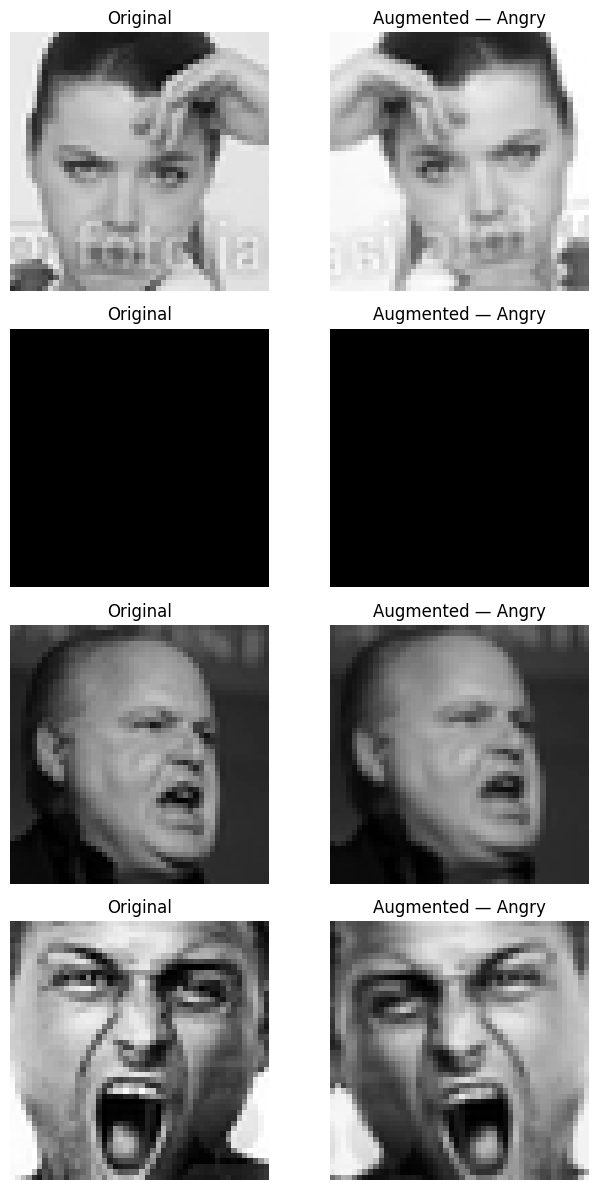

In [ ]:
number_to_show = min(4, len(extra_images))

if number_to_show > 0:
    fig, axes = plt.subplots(
        number_to_show,
        2,
        figsize=(7, 3 * number_to_show),
        squeeze=False
    )

    for i in range(number_to_show):
        original = np.fromstring(
            train_df.iloc[source_indices[i]]["pixels"],
            sep=" ",
            dtype=np.uint8
        ).reshape(48, 48)

        axes[i, 0].imshow(
            original, cmap="gray", vmin=0, vmax=255
        )
        axes[i, 0].set_title("Original")

        axes[i, 1].imshow(
            extra_images[i], cmap="gray", vmin=0, vmax=255
        )
        axes[i, 1].set_title(
            f"Augmented — {class_names[int(extra_labels[i])]}"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
RUN_AUGMENTED_HOG = True

if RUN_AUGMENTED_HOG:
    extra_hog = []

    for image in extra_images:
        features = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        extra_hog.append(features)

    extra_hog = np.asarray(
        extra_hog, dtype=np.float32
    ).reshape(-1, X_train_hog.shape[1])
else:
    print('Augmented HOG skipped; reuse augmented features in this kernel.')

# Add training features without changing validation data.
X_train_augmented = np.concatenate(
    [X_train_hog, extra_hog],
    axis=0
)

y_train_augmented = np.concatenate(
    [y_train, extra_labels]
)

print("Original training shape:", X_train_hog.shape)
print("Augmented training shape:", X_train_augmented.shape)


Original training shape: (28709, 900)
Augmented training shape: (31045, 900)


In [ ]:
RUN_AUGMENTATION_TRAINING = True

if RUN_AUGMENTATION_TRAINING:
    augmented_model = clone(baseline_model)

    augmented_model.set_params(class_weight=None)

    augmented_model.fit(
            X_train_augmented,
            y_train_augmented
        )
else:
    print("Augmentation training skipped; reuse the fitted augmented model.")

augmented_predictions = augmented_model.predict(
        X_valid_hog
    )

record_result("RF minority augmentation, no weights", augmented_model, augmented_predictions)

augmentation_result = {
        "Model": "Minority augmentation, no weights",
        "Accuracy": accuracy_score(
            y_valid, augmented_predictions
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_valid, augmented_predictions
        ),
        "Macro F1": f1_score(
            y_valid,
            augmented_predictions,
            labels=range(7),
            average="macro",
            zero_division=0
        )
    }

display(pd.DataFrame([augmentation_result]).round(3))

print(classification_report(
        y_valid,
        augmented_predictions,
        labels=range(7),
        target_names=class_names,
        zero_division=0
    ))


,Model,Accuracy,Balanced accuracy,Macro F1
0,"Minority augmentation, no weights",0.454,0.4,0.406


              precision    recall  f1-score   support

       Angry       0.58      0.16      0.25       467
     Disgust       0.78      0.32      0.46        56
        Fear       0.61      0.16      0.25       496
       Happy       0.41      0.90      0.57       895
         Sad       0.44      0.22      0.29       653
    Surprise       0.61      0.66      0.63       415
     Neutral       0.40      0.39      0.40       607

    accuracy                           0.45      3589
   macro avg       0.55      0.40      0.41      3589
weighted avg       0.49      0.45      0.41      3589



## 8. Random Forest hyperparameter tuning

The optional search compares tree depths of 11, 20 and no depth limit. It also compares minimum leaf sizes of 1 and 3. The recorded run skips the search and fits the fixed depth-20, leaf-1 model.

In [ ]:
RUN_TUNING = False

best_depth = 20
best_leaf = 1
tuning_results = []

if RUN_TUNING:

    best_depth = 11
    best_leaf = 1
    best_tuning_f1 = reference_result["Macro F1"]

    for depth in [11, 20, None]:
        for minimum_leaf in [1, 3]:

            print(
                "Training:",
                "depth =", depth,
                "minimum leaf =", minimum_leaf
            )

            model = create_forest(
                depth=depth,
                minimum_leaf=minimum_leaf
            )

            model.fit(X_train_hog, y_train)

            predictions = model.predict(X_valid_hog)

            result = evaluate_predictions(
                f"Depth {depth}, leaf {minimum_leaf}",
                predictions
            )

            tuning_results.append(result)
            record_result(result["Experiment"], model, predictions)

            if result["Macro F1"] > best_tuning_f1:
                best_tuning_f1 = result["Macro F1"]
                best_depth = depth
                best_leaf = minimum_leaf

    tuning_table = pd.DataFrame(tuning_results)

    display(
        tuning_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )

    print("Selected depth:", best_depth)
    print("Selected minimum leaf size:", best_leaf)

else:
    print("Tuning skipped.")


Tuning skipped.


In [ ]:
RUN_BEST_FOREST_TRAINING = True

if RUN_BEST_FOREST_TRAINING:
    if best_depth == 11 and best_leaf == 1:
        best_model = reference_model
    else:
        best_model = create_forest(depth=best_depth, minimum_leaf=best_leaf)
        best_model.fit(X_train_hog, y_train)
else:
    print('Tuned forest training skipped; reuse the fitted model.')

best_predictions = best_model.predict(X_valid_hog)
best_result = record_result(
    f"RF tuned: depth {best_depth}, leaf {best_leaf}",
    best_model, best_predictions
)
display(pd.DataFrame([reference_result, best_result]).round(3))


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"Reference: 0.75 weights, all features",0.461,0.408,0.422
1,"RF tuned: depth 20, leaf 1",0.468,0.402,0.426


## 9. SVM with unscaled HOG features

The following cells compare two SVMs with C=1 and gamma="scale". Only the class weights change.

In [ ]:
RUN_SVM_COMPARISON = True

if RUN_SVM_COMPARISON:
    svm_baseline = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=None
    )

    svm_weighted = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=selected_weights
    )

    svm_baseline.fit(X_train_hog, y_train)
    svm_weighted.fit(X_train_hog, y_train)
else:
    print('Unscaled SVM training skipped; reuse both fitted models.')


In [ ]:
svm_results = []

models = {
        "SVM baseline": svm_baseline,
        "SVM with 0.75 weights": svm_weighted
    }

for name, model in models.items():
        print("Evaluating:", name)

        predicted = model.predict(X_valid_hog)

        result = record_result(name + " (unscaled)", model, predicted)
        svm_results.append(result)

svm_table = pd.DataFrame(svm_results)

display(
        svm_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )


Training: SVM baseline
Training: SVM with 0.75 weights


,Experiment,Accuracy,Balanced accuracy,Macro F1
1,SVM with 0.75 weights (unscaled),0.533,0.520,0.535
0,SVM baseline (unscaled),0.535,0.474,0.495


In [ ]:
for name, model in models.items():
    predicted = model.predict(X_valid_hog)

    print("\n", name)

    print(classification_report(
        y_valid,
        predicted,
        labels=range(7),
        target_names=class_names,
        zero_division=0
    ))



 SVM baseline
              precision    recall  f1-score   support

       Angry       0.43      0.38      0.40       467
     Disgust       1.00      0.23      0.38        56
        Fear       0.43      0.30      0.35       496
       Happy       0.64      0.78      0.70       895
         Sad       0.42      0.44      0.43       653
    Surprise       0.75      0.63      0.69       415
     Neutral       0.48      0.54      0.51       607

    accuracy                           0.54      3589
   macro avg       0.59      0.47      0.50      3589
weighted avg       0.54      0.54      0.53      3589


 SVM with 0.75 weights
              precision    recall  f1-score   support

       Angry       0.39      0.42      0.41       467
     Disgust       0.83      0.54      0.65        56
        Fear       0.42      0.32      0.36       496
       Happy       0.70      0.71      0.70       895
         Sad       0.41      0.44      0.43       653
    Surprise       0.68      0.68      

## 10. SVM with scaled HOG features

The pipeline fits a scaler on Training and applies it to PublicTest. The following cells compare unweighted and weighted SVMs with the same settings.


In [ ]:
RUN_SCALED_SVM_TRAINING = True

if RUN_SCALED_SVM_TRAINING:
    svm_scaled_baseline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42))
    ])
    svm_scaled_weighted = clone(svm_scaled_baseline)
    svm_scaled_weighted.set_params(svm__class_weight=selected_weights)

    for name, model in {
        "SVM scaled baseline": svm_scaled_baseline,
        "SVM scaled, 0.75 weights": svm_scaled_weighted
    }.items():
        print("Training:", name)
        model.fit(hog_feats, labelsTrain)
else:
    print('Scaled SVM training skipped; reuse the fitted pipelines.')

scaled_svm_results = []
for name, model in {
    "SVM scaled baseline": svm_scaled_baseline,
    "SVM scaled, 0.75 weights": svm_scaled_weighted
}.items():
    scaled_svm_results.append(record_result(name, model))

display(pd.DataFrame(scaled_svm_results).round(3))


Training: SVM scaled baseline
Training: SVM scaled, 0.75 weights


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,SVM scaled baseline,0.542,0.482,0.505
1,"SVM scaled, 0.75 weights",0.542,0.524,0.543


## 11. SVM hyperparameter tuning

The following cells search over C and gamma using three-fold cross-validation within Training. Each fold fits its own scaler. The selected candidate is then evaluated on PublicTest.

In [ ]:
RUN_SVM_TUNING = False

if RUN_SVM_TUNING:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", random_state=42))
    ])

    param_grid = [
        {"svm__C": [1], "svm__gamma": ["scale"]},
        {"svm__C": [1], "svm__gamma": [0.01]},
        {"svm__C": [10], "svm__gamma": [0.001]},
        {"svm__C": [10], "svm__gamma": [0.01]}
    ]

    svm_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=3,
        n_jobs=1,
        verbose=2
    )

    start_time = time.time()

    # Fit scaling separately inside each training fold.
    svm_search.fit(hog_feats, labelsTrain)

    elapsed = (time.time() - start_time) / 60

    print("Best parameters:", svm_search.best_params_)
    print("Best CV Macro-F1:", round(svm_search.best_score_, 4))
    print("Elapsed time (minutes):", round(elapsed, 2))
else:
    print("SVM tuning skipped; no search winner is assumed.")


SVM tuning skipped; no search winner is assumed.


In [ ]:
if RUN_SVM_TUNING:

    best_svm = svm_search.best_estimator_

    y_pred_tuned = best_svm.predict(hog_valid)

    record_result("SVM scaled, tuned by training CV", best_svm, y_pred_tuned)

    accuracy_tuned = accuracy_score(y_valid, y_pred_tuned)
    balanced_acc_tuned = balanced_accuracy_score(y_valid, y_pred_tuned)
    macro_f1_tuned = f1_score(y_valid, y_pred_tuned, average="macro")

    print("Tuned SVM + HOG (Pipeline) — PublicTest")
    print(f"Accuracy: {accuracy_tuned:.4f}")
    print(f"Balanced Accuracy: {balanced_acc_tuned:.4f}")
    print(f"Macro-F1: {macro_f1_tuned:.4f}")

    cm_tuned = confusion_matrix(y_valid, y_pred_tuned, labels=list(range(7)))

    emotion_labels = [
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ]

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm_tuned,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=emotion_labels,
        yticklabels=emotion_labels
    )
    plt.xlabel("Predicted emotion")
    plt.ylabel("True emotion")
    plt.title("Confusion Matrix — Tuned RBF SVM + HOG (PublicTest)")
    plt.tight_layout()
    plt.show()
else:
    print("No tuned SVM result in this run.")


No tuned SVM result in this run.


## 12. SVM feature selection

ANOVA selects 675 of the 900 HOG features using Training only. The following cells compare selected features with all features. Both SVMs use the same scaling, C=10, gamma=0.001 and no class weights.

In [ ]:
# Reuse the scaler fitted on Training.
scaler_hog = svm_scaled_baseline.named_steps["scaler"]
hog_feats_scaled = scaler_hog.transform(hog_feats)
hog_valid_scaled = scaler_hog.transform(hog_valid)

RUN_SELECTION_CONTROL_TRAINING = True

# Match the full-feature model to the selected-feature model.
if RUN_SELECTION_CONTROL_TRAINING:

    if (
        RUN_SVM_TUNING
        and best_svm.get_params()["svm__C"] == 10
        and best_svm.get_params()["svm__gamma"] == 0.001
    ):
        svm_selection_control = best_svm
    else:
        svm_selection_control = clone(svm_scaled_baseline)
        svm_selection_control.set_params(svm__C=10, svm__gamma=0.001)
        svm_selection_control.fit(hog_feats, labelsTrain)
else:
    print('Control SVM training skipped; reuse the fitted control.')

selection_control_result = record_result(
    "SVM selection control: 900 features, C=10, gamma=0.001",
    svm_selection_control
)


In [ ]:
RUN_SVM_FEATURE_SELECTION = True

if RUN_SVM_FEATURE_SELECTION:

    k = int(hog_feats_scaled.shape[1] * 0.75)

    selector_75 = SelectKBest(score_func=f_classif, k=k)

    X_train_selected_75 = selector_75.fit_transform(
        hog_feats_scaled, labelsTrain
    )

    X_valid_selected_75 = selector_75.transform(
        hog_valid_scaled
    )

    print("Original number of features:", hog_feats_scaled.shape[1])
    print("Selected number of features:", X_train_selected_75.shape[1])
else:
    print('ANOVA selection skipped; reuse the fitted selector and feature subsets.')


Original number of features: 900
Selected number of features: 675


In [ ]:
RUN_SELECTED_SVM_TRAINING = True

if RUN_SELECTED_SVM_TRAINING:
    svm_selected_75 = SVC(
        kernel="rbf",
        C=10,
        gamma=0.001,
        random_state=42
    )

    svm_selected_75.fit(X_train_selected_75, labelsTrain)
else:
    print('Selected-feature SVM training skipped; reuse the fitted model.')

y_pred_selected_75 = svm_selected_75.predict(X_valid_selected_75)

print(f"Accuracy: {accuracy_score(y_valid, y_pred_selected_75):.4f}")
print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_valid, y_pred_selected_75):.4f}"
)
print(
    f"Macro-F1: "
    f"{f1_score(y_valid, y_pred_selected_75, average='macro'):.4f}"
)

# Apply the fitted scaler and selector before prediction.
svm_selected_pipeline = Pipeline([
    ("scaler", scaler_hog),
    ("selector", selector_75),
    ("svm", svm_selected_75)
])
selected_svm_result = record_result(
    "SVM ANOVA: 675 features, C=10, gamma=0.001",
    svm_selected_pipeline, y_pred_selected_75
)
display(pd.DataFrame([
    selection_control_result, selected_svm_result
]).round(3))


Accuracy: 0.5592
Balanced Accuracy: 0.5343
Macro-F1: 0.5543


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"SVM selection control: 900 features, C=10, gam...",0.566,0.537,0.559
1,"SVM ANOVA: 675 features, C=10, gamma=0.001",0.559,0.534,0.554


## 13. Forest feature-selection and leaf-size experiments

The following cells can rank HOG features with mutual information and compare 100, 300 and 600 features. They can also test minimum leaf sizes of 5, 10 and 20. PublicTest is used to compare the settings. Both searches are skipped in the recorded outputs. All 900 features are kept, and the fitted forest is reused.

In [ ]:
RUN_FEATURE_SELECTION = False

RUN_FEATURE_RANKING = RUN_FEATURE_SELECTION

if RUN_FEATURE_RANKING:
    mi_scores = mutual_info_classif(
        X_train_hog,
        y_train,
        discrete_features=False,
        random_state=42
    )

    # Rank the most informative features first.
    feature_ranking = np.argsort(mi_scores)[::-1]

    print("Feature ranking completed.")
    print("Number of features:", len(feature_ranking))

else:
    print("Feature ranking skipped.")


Feature ranking skipped.


In [ ]:
# Keep all features unless selection improves validation macro F1.
best_k = X_train_hog.shape[1]
best_selection_f1 = reference_result["Macro F1"]
selection_results = []

if RUN_FEATURE_SELECTION:

    for k in [100, 300, 600]:
        print("Training with", k, "features")

        # Preserve the original order of the chosen columns.
        selected_columns = np.sort(feature_ranking[:k])

        train_subset = X_train_hog[:, selected_columns]
        valid_subset = X_valid_hog[:, selected_columns]

        model = create_forest(
            depth=11,
            minimum_leaf=1
        )

        model.fit(train_subset, y_train)

        predictions = model.predict(valid_subset)

        result = evaluate_predictions(
            f"Feature selection: {k} features",
            predictions
        )

        selection_results.append(result)
        record_result(result["Experiment"], model, predictions, columns=selected_columns)

        if result["Macro F1"] > best_selection_f1:
            best_selection_f1 = result["Macro F1"]
            best_k = k

    selection_table = pd.DataFrame(selection_results)

    display(
        selection_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )

    print("Selected number of features:", best_k)

else:
    print("Feature selection skipped.")


Feature selection skipped.


In [ ]:
if best_k == X_train_hog.shape[1]:
    best_columns = np.arange(X_train_hog.shape[1])
    # Reuse the fitted model when no features are removed.
    combined_model = best_model
    combined_predictions = best_predictions
    print("All 900 features retained; reuse the tuned forest without refitting.")
else:
    best_columns = np.sort(feature_ranking[:best_k])
    combined_model = create_forest(depth=best_depth, minimum_leaf=best_leaf)
    combined_model.fit(X_train_hog[:, best_columns], y_train)
    combined_predictions = combined_model.predict(X_valid_hog[:, best_columns])
    record_result(
        f"RF tuned with MI selection: {best_k} features",
        combined_model, combined_predictions, columns=best_columns
    )


All 900 features retained; reuse the tuned forest without refitting.


In [ ]:
RUN_LEAF_SEARCH = False

if RUN_LEAF_SEARCH:
    leaf_results = []

    existing_train_predictions = best_model.predict(X_train_hog)

    leaf_results.append({
        **best_result,
        "Training macro F1": f1_score(
            y_train,
            existing_train_predictions,
            average="macro",
            zero_division=0
        )
    })

    for leaf_size in [5, 10, 20]:
        print("Training with minimum leaf size:", leaf_size)

        model = create_forest(
            depth=20,
            minimum_leaf=leaf_size
        )

        model.fit(X_train_hog, y_train)

        train_predictions = model.predict(X_train_hog)
        valid_predictions = model.predict(X_valid_hog)

        result = evaluate_predictions(
            f"Depth 20, leaf {leaf_size}",
            valid_predictions
        )

        result["Training macro F1"] = f1_score(
            y_train,
            train_predictions,
            average="macro",
            zero_division=0
        )

        leaf_results.append(result)
        record_result(result["Experiment"], model, valid_predictions)

    leaf_table = pd.DataFrame(leaf_results)

    leaf_table["F1 gap"] = (
        leaf_table["Training macro F1"]
        - leaf_table["Macro F1"]
    )

    display(
        leaf_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )

else:
    print("Leaf-size search skipped.")


Leaf-size search skipped.


## 14. Validation results

The next cell collects results from the evaluated models. It ranks them by PublicTest macro F1 and selects the highest score. PrivateTest is not used for selection.

In [ ]:
final_table = pd.DataFrame(validation_results).sort_values(
    "Macro F1", ascending=False, kind="stable"
).reset_index(drop=True)
display(final_table.round(3))

selected_name = final_table.iloc[0]["Experiment"]
final_model, final_columns = candidate_models[selected_name]
print("Selected using validation macro F1:", selected_name)


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"SVM selection control: 900 features, C=10, gam...",0.566,0.537,0.559
1,"SVM ANOVA: 675 features, C=10, gamma=0.001",0.559,0.534,0.554
2,"SVM scaled, 0.75 weights",0.542,0.524,0.543
3,SVM with 0.75 weights (unscaled),0.533,0.520,0.535
4,SVM scaled baseline,0.542,0.482,0.505
5,SVM baseline (unscaled),0.535,0.474,0.495
6,RF balanced weights,0.469,0.432,0.439
7,"RF tuned: depth 20, leaf 1",0.468,0.402,0.426
8,"RF 0.75 weights, depth 11",0.461,0.408,0.422
9,"RF minority augmentation, no weights",0.454,0.400,0.406


Selected using validation macro F1: SVM selection control: 900 features, C=10, gamma=0.001


The scaled SVM with all 900 features, C=10, gamma=0.001 and no class weights ranks first. Its accuracy is 0.566, balanced accuracy is 0.537 and macro F1 is 0.559.

## 15. Training-validation gaps

The next cell compares training and validation scores for the reference forest, weighted unscaled SVM and selected model.



In [ ]:
RUN_GAP_CHECK = True

if RUN_GAP_CHECK:
    models_to_check = {
        "RF reference: depth 11": (reference_model, None),
        "SVM weighted (unscaled)": (svm_weighted, None),
        "Selected model": (final_model, final_columns)
    }
    rows = []
    for name, (model, columns) in models_to_check.items():
        train_features = X_train_hog if columns is None else X_train_hog[:, columns]
        valid_features = X_valid_hog if columns is None else X_valid_hog[:, columns]
        train_predictions = model.predict(train_features)
        valid_predictions = model.predict(valid_features)
        train_f1 = f1_score(y_train, train_predictions, labels=classes,
                            average="macro", zero_division=0)
        valid_f1 = f1_score(y_valid, valid_predictions, labels=classes,
                            average="macro", zero_division=0)
        rows.append({
            "Model": name,
            "Training accuracy": accuracy_score(y_train, train_predictions),
            "Validation accuracy": accuracy_score(y_valid, valid_predictions),
            "Training macro F1": train_f1,
            "Validation macro F1": valid_f1,
            "F1 gap": train_f1 - valid_f1
        })
    display(pd.DataFrame(rows).round(3))
else:
    print('Gap calculation skipped; keep the previous diagnostic output.')


,Model,Training accuracy,Validation accuracy,Training macro F1,Validation macro F1,F1 gap
0,RF reference: depth 11,0.971,0.461,0.975,0.422,0.553
1,SVM weighted (unscaled),0.767,0.533,0.791,0.535,0.256
2,Selected model,0.998,0.566,0.998,0.559,0.439


The selected SVM has training macro F1 0.998 and validation macro F1 0.559. The gap is 0.439, which suggests substantial overfitting. The weighted unscaled SVM has a smaller gap of 0.256, but also a lower validation macro F1 of 0.535.

## 16. Discussion

Class weighting improves average performance across emotions. Augmentation gives a smaller gain for the forest. ANOVA reduces the feature count but slightly lowers validation performance.

The selected full-feature SVM has the highest validation macro F1. Its large training-validation gap remains a limitation. A higher validation score does not mean that overfitting has been removed.

## 17. Final PrivateTest evaluation

The following cells apply the selected model to PrivateTest. They report accuracy, balanced accuracy, macro F1 and a confusion matrix. The model and its preprocessing remain fitted on Training.

**Run status:** PrivateTest evaluation is disabled in the recorded outputs. Enable `RUN_FINAL_TEST` only after fixing the model choice. Test scores must not be used to choose new settings.

In [ ]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    test_df = pd.read_csv(BASE / "data/fer2013_test.csv")
    y_test = test_df["emotion"].to_numpy()
    X_test_hog = extract_hog_from_dataframe(test_df)
    assert X_test_hog.shape == (len(y_test), X_train_hog.shape[1])

    test_features = (
        X_test_hog if final_columns is None else X_test_hog[:, final_columns]
    )
    # The model and its preprocessing are already fitted.
    y_pred_private = final_model.predict(test_features)
    private_result = {
        "Model": selected_name,
        "Accuracy": accuracy_score(y_test, y_pred_private),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred_private),
        "Macro F1": f1_score(y_test, y_pred_private, labels=classes,
                             average="macro", zero_division=0)
    }
    display(pd.DataFrame([private_result]).round(3))
    print(classification_report(
        y_test, y_pred_private, labels=classes,
        target_names=class_names, zero_division=0
    ))
else:
    print("PrivateTest is held aside. Enable RUN_FINAL_TEST after freezing the configuration.")


PrivateTest is held aside. Enable RUN_FINAL_TEST after freezing the configuration.


In [ ]:
if RUN_FINAL_TEST:
    cm_private = confusion_matrix(
        y_test,
        y_pred_private,
        labels=list(range(7))
    )

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm_private,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted emotion")
    plt.ylabel("True emotion")
    plt.title("Selected model — PrivateTest")
    plt.tight_layout()
    plt.show()
